# Do algorithm bans pick a substitute or a ladder? FRLP screen on Qwen3-8B (demo)

When a prompt says *"Do not use breadth-first search (BFS) for this task"*, the model's probability mass leaves BFS. Where does it go? Two accounts compete:

* **X-specific substitution**: the ban picks particular substitutes (banning BFS lifts DFS more than anything else), perhaps the ones the model *associates* with the banned name.
* **Generic ladder**: the mass moves along a fixed profile that **any** perturbation of the prompt produces: a nonsense ban (*"the Zorblax method"*), matched-norm random edits of the prompt's hidden states, or a *"write a novel algorithm"* instruction.

The artifact tests this claim (C1) on **Qwen/Qwen3-8B** (thinking off) and two path-search tasks: **T1** grid path with 6 algorithms (BFS, DFS, bidirectional BFS, IDDFS, A*, unit-weight Dijkstra), and **T2** weighted shortest path with 5 (Dijkstra, Bellman-Ford/SPFA, bidirectional Dijkstra, Floyd-Warshall, Dial).

**Instrument: forced-ratio latent probabilities (FRLP).** Sampling cannot measure algorithms the model almost never writes. Instead, programs of every algorithm $j$ are *forced* (generated under 10 paraphrases such as *"Implement $j$ for this task"*), labelled by running them, scrubbed of algorithm names, and then **teacher-forced** under every prompt condition $c$. Importance sampling turns these log-likelihoods into an estimate of $\log P(\text{model writes } j \mid c)$:

$$L_j(c) = \log y_j + \log \frac{1}{|P|} \sum_{m \in P} \exp\big[\ell(p_m \mid c) - \ell_q(p_m)\big], \qquad \ell_q(p) = \log \frac{1}{10} \sum_{k=1}^{10} P(p \mid F_j^k),$$

where $y_j$ is the share of forced attempts that really implement $j$ (yield correction).

**What this notebook runs.** `method.py` orchestrates 13 stages. The GPU stages cannot run in a short demo: vLLM generated 1,170 forced programs, and teacher-forced scoring of 684 condition x program-set units took about 3.3 GPU-hours on an L4. Their output is loaded from `mini_demo_data.json` instead: **99 of the 211 scored programs** (the first 9 per algorithm by their pre-registered selection rank), each with its log-likelihood under every scored condition. The CPU stages then run with the original code:

| section | original file | what it computes |
|---|---|---|
| 3 | `src/frlp.py`, `src/analysis_misc.py` | FRLP cells, mixture-identity check, effective sample sizes (ESS) |
| 4 | `src/gate.py` | FRLP validity gate against 19 events sampled in iteration 1 |
| 5 | `src/c1.py` | C1 share test (ladder vs X-specific), AIM tests, sensitivity, shams, two-step bans |
| 6 | `audit/rederive.py` | independent re-derivation of the headline numbers |
| 7 | `src/outputs.py` | tables and figures, next to the full run (M = 20 programs per algorithm) |

**Full-run results, for orientation.**

* The gate fails on calibration (a): the scrubbed programs give DFS too much mass under the T1 baseline. The *unscrubbed* programs pass all three gate criteria, so the failure is a name-scrubbing artifact.
* The pooled X-specific SHARE is 0.55 [0.25, 0.67] with neutral twins, so the branch is UNDETERMINED.
* The residuals are not aimed at the prime-and-veto profile (AIM -0.10, p = 0.80), and the generic profiles do not form a coherent ladder.

With 9 instead of 20 programs per algorithm the demo numbers are noisier, but they come from the same pipeline.

In [1]:
import subprocess, sys
def _pip(*a): subprocess.check_call([sys.executable, '-m', 'pip', 'install', '-q', *a])

# loguru, rapidfuzz — NOT on Colab, always install (same pins as the artifact's pyproject.toml)
_pip('loguru==0.7.3', 'rapidfuzz==3.14.6')

# numpy, pandas, scipy, matplotlib — pre-installed on Colab, install locally only (Colab's exact versions)
if 'google.colab' not in sys.modules:
    _pip('numpy==2.0.2', 'pandas==2.2.2', 'scipy==1.16.3', 'matplotlib==3.10.0')

In [2]:
from __future__ import annotations

# imports of src/config.py, src/frlp.py, src/analysis_misc.py, src/gate.py, src/c1.py, audit/rederive.py, src/outputs.py
import collections
import io
import json
import keyword
import math
import random
import sys
import time
import tokenize
import warnings
from dataclasses import dataclass, field
from datetime import datetime, timezone
from typing import Any

import numpy as np
import pandas as pd
from loguru import logger
from scipy.stats import rankdata, spearmanr

import matplotlib.pyplot as plt

# config.setup_logging(): loguru to stdout (the original also added a file sink logs/<stage>.log)
logger.remove()
logger.add(sys.stdout, level="INFO", format="{time:HH:mm:ss}|{level:<7}|{message}")
# outputs.py figure style
plt.rcParams.update({"font.size": 9, "axes.spines.top": False, "axes.spines.right": False, "pdf.fonttype": 42})
# np.nanmean over conditions that were never scored (e.g. the dropped Q8 shams) returns NaN by design
warnings.filterwarnings("ignore", category=RuntimeWarning, message="Mean of empty slice")

In [3]:
GITHUB_DATA_URL = "https://raw.githubusercontent.com/ai-inventor-papers/ai-invention-295f8e-prompt-bans-substitute-not-just-subtract/fork/run_jSassd-YWLVC/round-2/experiment-7/demo/mini_demo_data.json"
import http.client
import json
import urllib.request
from pathlib import Path

def load_data():
    try:
        with urllib.request.urlopen(GITHUB_DATA_URL, timeout=15) as response:
            return json.loads(response.read().decode())
    # Network errors, timeouts, a placeholder URL, bad JSON, a cut-off response.
    except (OSError, ValueError, http.client.HTTPException) as e:
        print("GitHub data unavailable, using local mini_demo_data.json:", e)
    local = Path("mini_demo_data.json")
    if local.exists(): return json.loads(local.read_text())
    raise FileNotFoundError("Could not load mini_demo_data.json")

In [4]:
data = load_data()
META = data["metadata"]
EXAMPLES = data["datasets"][0]["examples"]   # one forced program per example
print(f"{len(EXAMPLES)} forced programs, {sum(len(e['scores']) for e in EXAMPLES):,} teacher-forced scores "
      f"(columns {META['score_columns']}); demo M = {META['M_demo']} programs per algorithm "
      f"(full run M = {META['M_full_run']})")

GitHub data unavailable, using local mini_demo_data.json: HTTP Error 404: Not Found
99 forced programs, 17,625 teacher-forced scores (columns ['total', 'body', 'cum256']); demo M = 9 programs per algorithm (full run M = 20)


## Configuration

All tunable parameters are in the next cell, with the full run's values in the comments.

* The bootstrap, permutation and placebo sizes are at the **full run's values**; the whole notebook still finishes in a few minutes on a 2-CPU machine.
* `M_SCORED` is the one parameter capped by the data. `mini_demo_data.json` holds the first 9 programs per algorithm, while the full run scored 20 (the pre-registered cut rule set M = 20 after measuring the scorer's throughput).

Lower `N_BOOT`, `N_PERM` and `SENS_BOOT` for a quicker pass.

In [5]:
# ---- tunable parameters (full-run values in the comments) ----
M_SCORED = 9            # forced programs per algorithm in every FRLP cell (full run: 20). The demo data holds the
                        # first 9 per algorithm by selection rank; 7 is the smallest value at which every
                        # algorithm-half still has a program
GATE_PARAPHRASES = 3    # iteration-1 paraphrases per gate event (full run: 3, the only ones scored)
N_BOOT = 2_000          # C1 bootstrap replicates (full run: 2,000)
N_PERM = 200_000        # Monte Carlo draws of each AIM permutation null (full run: 200,000)
SENS_BOOT = 400         # bootstrap replicates per sensitivity variant (full run: 400)
SENS_PERM = 20_000      # null draws per sensitivity variant (full run: 20,000)
N_PLACEBO = 200         # placebo permutations in the independent re-derivation (full run: 200)

### Frozen protocol (`src/config.py`)

Every stage reads its names, templates, seeds and thresholds from `config.py`, so the protocol has one definition. The constants below are copied verbatim. Left out are the file paths, the I/O and hash-chain helpers, and the generation-only helpers; `N_BOOT` and `N_PERM` come from the configuration cell.

How the prompt conditions are built:

* A **ban** prepends a sentence such as *"Do not use {X} for this task."* to the task statement.
* Its **mention twin** says *"You could use {X} for this task."*
* Its **neutral twin** bans a frequent noun instead (*"Do not use man for this task. . . . . . ."*), padded with `' .'` so that it has exactly as many tokens as the ban.

Each of the five templates W1–W5 has all three forms.

In [6]:
MODEL_ID = "Qwen/Qwen3-8B"
MODEL_REV = "b968826d9c46dd6066d109eabc6255188de91218"
CHAT_TAIL = "<|im_start|>assistant\n<think>\n\n</think>\n\n"

TASKS = ("t1", "t2")
MODES: dict[str, list[str]] = {
    "t1": ["bfs", "dfs", "bibfs", "iddfs", "astar_gbfs", "dijkstra"],
    "t2": ["dijkstra", "bf_spfa", "bidijkstra", "floyd", "dial"],
}
DEFAULT_MODE = {"t1": "bfs", "t2": "dijkstra"}
OTHER = "other"
# Frozen display names (direction); NOT exp1's t1 names for astar_gbfs / dijkstra.
DISPLAY: dict[str, dict[str, str]] = {
    "t1": {
        "bfs": "breadth-first search (BFS)",
        "dfs": "depth-first search (DFS)",
        "bibfs": "bidirectional BFS",
        "iddfs": "iterative deepening DFS (IDDFS)",
        "astar_gbfs": "A* search",
        "dijkstra": "unit-weight Dijkstra",
    },
    "t2": {
        "dijkstra": "Dijkstra's algorithm",
        "bf_spfa": "Bellman-Ford or SPFA",
        "bidijkstra": "bidirectional Dijkstra",
        "floyd": "Floyd-Warshall",
        "dial": "Dial's bucket-queue algorithm",
    },
}
SHAMS: dict[str, dict[str, str]] = {
    "t1": {"jps": "jump point search", "idastar": "IDA* search"},
    "t2": {"johnson": "Johnson's algorithm", "yen": "Yen's k-shortest-paths algorithm"},
}
# Pre-declared content neighbours of each off-catalogue sham (step 7.3).
SHAM_NEIGHBOURS = {"idastar": ["iddfs", "astar_gbfs"], "jps": ["astar_gbfs"], "johnson": ["bf_spfa", "dijkstra"],
                   "yen": ["dijkstra"]}
NONCE = "the Zorblax method"
TWO_STEP = {"t1": ["bfs", "dfs"], "t2": ["dijkstra", "bf_spfa"]}
WS = ["W1", "W2", "W3", "W4", "W5"]
TEMPLATES: dict[str, dict[str, str]] = {
    "W1": {"ban": "Do not use {X} for this task.", "mention": "You could use {X} for this task.",
           "neutral": "Do not use {N} for this task."},
    "W2": {"ban": "Your solution must not rely on {X}.", "mention": "Your solution may rely on {X}.",
           "neutral": "Your solution must not rely on {N}."},
    "W3": {"ban": "Avoid {X} entirely.", "mention": "Consider {X} first.", "neutral": "Avoid {N} entirely."},
    "W4": {"ban": "{X} is not allowed here.", "mention": "{X} is allowed here.", "neutral": "{N} is not allowed here."},
    "W5": {"ban": "Write a correct solution that does not use {X}.",
           "mention": "Write a correct solution that may use {X}.",
           "neutral": "Write a correct solution that does not use {N}."},
}
NOVELTY = "Write a novel algorithm for this task, one you have not seen before."
FORCED_TEMPLATES = [
    "Implement {j} for this task.", "Use {j} to solve this task.", "Solve this task with {j}.",
    "Your solution should use {j}.", "Write an implementation based on {j}.", "Solve this task by implementing {j}.",
    "Please implement {j} for this task.", "The solution must use {j}.", "Write a solution that uses {j}.",
    "Apply {j} to this task.",
]
FREE_TEMPLATE = "What is the standard alternative to {X} for this task? Answer with the name of one algorithm only."
FILLERS = [" .", " -", " ok"]
EDIT_LAYERS = list(range(12, 25))      # decoder layers 12..24 (outputs = hidden_states[l+1])
RAND_SEEDS = {"A": [1001, 1002, 1003], "B": [2001, 2002, 2003]}
VARIANT_II_LAYER = 18
VARIANT_II_COEF = 0.25
N_FORCED_TARGET = 30
MIN_MEASURABLE = 10
SEED_SELECT = 7
SEED_HALVES = 11
SEED_BOOT = 13
# N_BOOT = 2000 and N_PERM = 200_000 in the original: set in the configuration cell
ESS_FLAG = 5.0
GATE_A_S_RANGE = (0.3, 3.0)
GATE_A_M_MIN = 0.9
GATE_B_MIN = 0.3
GATE_C_MIN = 0.8
CLEAR_MODE_MARGIN = 0.15
LADDER_COS_MIN = 0.5
TRUNC_TOKENS = [64, 128, 256, 384]

# Name lexicon for scrubbing (step 2.2), case-insensitive, word/underscore boundaries.
SCRUB_PHRASES = [
    r"breadth[- ]first", r"depth[- ]first", r"bi[- ]?directional", r"iterative[- ]deepening", r"greedy best[- ]first",
    r"best[- ]first", r"bellman[- ]?ford", r"shortest path faster", r"uniform[- ]cost", r"jump point", r"A\*",
    r"A-star", r"IDA\*", r"BFS", r"DFS", r"IDDFS", r"astar", r"a_star", r"GBFS", r"Dijkstra'?s?", r"SPFA",
    r"Floyd", r"Warshall", r"Dial'?s?", r"UCS", r"JPS", r"Johnson'?s?", r"Yen'?s?",
]
SCRUB_STEMS = ["bfs", "dfs", "iddfs", "dijkstra", "bellman", "spfa", "floyd", "warshall", "astar", "a_star", "dial",
               "bidir", "gbfs", "jps", "johnson", "yen", "bibfs", "bidijkstra", "ucs", "idastar"]


def utc_now() -> str:
    return datetime.now(timezone.utc).strftime("%Y-%m-%dT%H:%M:%S.%fZ")


def logsumexp(a, axis=None):
    import numpy as np

    a = np.asarray(a, dtype=np.float64)
    m = np.max(a, axis=axis, keepdims=True)
    m = np.where(np.isfinite(m), m, 0.0)
    out = np.log(np.sum(np.exp(a - m), axis=axis, keepdims=True)) + m
    return np.squeeze(out, axis=axis) if axis is not None else float(out.squeeze())

## 1. The pipeline (`method.py`)

`method.py` is an orchestrator. Each stage is a script in `src/` that resumes from what is already on disk, and `run()` launches it as a subprocess with `cwd=src/`, so vLLM and the Hugging Face scorer never share a process. `uv run method.py all` runs the stages in `ORDER`.

The cell below keeps the stage table and prints what this notebook does with each stage, in place of launching it. The stages before the analysis need either the iteration-1 suite and data (0.1–0.4) or a GPU with Qwen3-8B (`generate`, `score`), and `select` runs candidate programs in a sandbox. Their outputs are what `mini_demo_data.json` contains.

In [7]:
STAGES = {
    "inputs": ["copy_inputs.py"],
    "recheck": ["labelling.py"],
    "events": ["gate_events.py"],
    "prompts": ["prompts_v2.py"],
    "generate": ["gen_vllm.py", "--max-num-seqs", "48"],
    "select": ["select_programs.py"],
    "score": ["frlp_score.py", "--deadline", "05:35", "--precision", "tf32"],
    "gate": ["gate.py"],
    "analyse_misc": ["analysis_misc.py"],
    "analyse": ["c1.py"],
    "freeze": ["freeze.py"],
    "outputs": ["outputs.py"],
    "audit": ["../audit/rederive.py"],
}
ORDER = ["inputs", "recheck", "events", "prompts", "generate", "select", "score", "gate", "analyse_misc", "analyse",
         "freeze", "outputs", "audit"]

# notebook: in place of run(stage) -> subprocess.run([python, src/<script>, *args], cwd=src/), where each stage's
# output comes from here
IN_THIS_NOTEBOOK = {
    "events": "loaded: 19 gate events + 2 two-step events (META['gate_events'])",
    "prompts": "loaded: prompt segments and nouns of all 604 conditions (META['prompts'])",
    "generate": "loaded: forced programs, labels and yields (EXAMPLES, META['yields'])",
    "select": "loaded: name-scrubbed, verified, selected programs with halves (EXAMPLES)",
    "score": "loaded: teacher-forced log-likelihoods (EXAMPLES[i]['scores'])",
    "analyse_misc": "run: FRLP cells, mixture identity, ESS table (section 3)",
    "gate": "run: section 4",
    "analyse": "run: section 5",
    "outputs": "run: tables and figures (section 7)",
    "audit": "run: section 6",
}
for st in ORDER:
    print(f"{st:<13} {' '.join(STAGES[st]):<52} "
          f"{IN_THIS_NOTEBOOK.get(st, 'not run here (needs the iteration-1 suite / writes frozen files)')}")

inputs        copy_inputs.py                                       not run here (needs the iteration-1 suite / writes frozen files)
recheck       labelling.py                                         not run here (needs the iteration-1 suite / writes frozen files)
events        gate_events.py                                       loaded: 19 gate events + 2 two-step events (META['gate_events'])
prompts       prompts_v2.py                                        loaded: prompt segments and nouns of all 604 conditions (META['prompts'])
generate      gen_vllm.py --max-num-seqs 48                        loaded: forced programs, labels and yields (EXAMPLES, META['yields'])
select        select_programs.py                                   loaded: name-scrubbed, verified, selected programs with halves (EXAMPLES)
score         frlp_score.py --deadline 05:35 --precision tf32      loaded: teacher-forced log-likelihoods (EXAMPLES[i]['scores'])
gate          gate.py                                  

## 2. The data: forced programs and their teacher-forced scores

Each example is one forced program and records:

* its algorithm `j` and its program half (`h1`/`h2`, which gives disjoint replicates);
* whether it passed the hidden tests;
* the raw code as generated;
* the **name-scrubbed** code that is actually scored (algorithm names in identifiers and comments are replaced, e.g. `def dfs` becomes `def find_path`).

`scores` maps `"<variant>|<condition>"` to the program's log-likelihood `[total, body, cum256]` under that condition's chat prompt. The three values cover the whole fenced response, the code body only, and the first 256 tokens. The keys are:

| key | condition |
|---|---|
| `primary\|forced\|<j>\|<family>\|k0..k9` | the 10 forced paraphrases, which give the mixture denominator $\ell_q$ |
| `primary\|ban\|<B>\|W1..W5` | bans |
| `primary\|mention\|<B>\|W1..W5` | mention twins |
| `primary\|neutral\|<B>\|W1..W5\|A/B` | neutral twins (noun A is scored on half h1, noun B on half h2) |
| `primary\|base0` | the task statement alone |
| `primary\|novelty` | the novelty instruction |
| `edit\|edit\|<seed>` | base0 with a matched-norm random edit of the prompt's hidden states in layers 12–24 |
| `primary\|exp1\|<event>\|p<k>` | the iteration-1 prompts of the gate events |
| `unscrubbed\|…` | the same programs scored *without* name scrubbing (for the gate diagnostic) |

In [8]:
ex = next(e for e in EXAMPLES if e["prog_id"] == "t1|dfs|0")
print(f"{ex['prog_id']}: label {ex['label']}, half {ex['half']}, passed {ex['passed']}, scrub mode {ex['scrub_mode']}")
print("---- raw code (as generated) ----")
print("\n".join(ex["code_raw"].splitlines()[:16]))
print("---- name-scrubbed code (what FRLP scores) ----")
print("\n".join(ex["code_scrubbed"].splitlines()[:16]))

seg = META["prompts"]["segments"]
print("\n---- sentence prepended to the task statement (empty for base0) ----")
for k in ["t1|forced|dfs|plain|k0", "t1|ban|bfs|W1", "t1|mention|bfs|W1", "t1|neutral|bfs|W1|A", "t1|neutral|bfs|W1|B",
          "t1|ban|nonce|W1", "t1|novelty", "t1|ban|two_step|W1"]:
    print(f"{k:<24} {seg[k]!r}")
print("\ntask statement T1:", META["prompts"]["task_spec"]["t1"][:300], "...")

print("\n---- teacher-forced log-likelihood of this program [total, body, cum256] ----")
for k in ["primary|forced|dfs|plain|k0", "primary|base0", "primary|ban|bfs|W1", "primary|mention|bfs|W1",
          "primary|neutral|bfs|W1|A", "unscrubbed|base0"]:
    print(f"{k:<30} {ex['scores'].get(k)}")

t1|dfs|0: label dfs, half h1, passed False, scrub mode full
---- raw code (as generated) ----
def solve(grid, start, goal):
    rows, cols = len(grid), len(grid[0])
    start_row, start_col = start
    goal_row, goal_col = goal

    if (start_row < 0 or start_row >= rows or start_col < 0 or start_col >= cols or
        grid[start_row][start_col] == '#' or
        grid[goal_row][goal_col] == '#'):
        return []

    directions = [(-1, 0), (1, 0), (0, -1), (0, 1)]

    def dfs(r, c, path):
        if (r, c) == (goal_row, goal_col):
            return path + [(r, c)]
        
---- name-scrubbed code (what FRLP scores) ----
def solve(grid, start, goal):
    rows, cols = len(grid), len(grid[0])
    start_row, start_col = start
    goal_row, goal_col = goal

    if (start_row < 0 or start_row >= rows or start_col < 0 or start_col >= cols or
        grid[start_row][start_col] == '#' or
        grid[goal_row][goal_col] == '#'):
        return []

    directions = [(-1, 0), (1, 0), (0, -1),

## 3. FRLP cells (`src/frlp.py`, step 4)

Take task $t$, condition $c$, algorithm $j$ and a set $P$ of forced $j$-programs. Each program gets a log importance weight $lw_m = \ell(p_m \mid c) - \ell_q(p_m)$, where $\ell_q$ is the balance-heuristic mixture over the algorithm's 10 forced paraphrases. Then:

* $L_j(c) = \log y_j + \operatorname{lse}_m(lw_m) - \log |P|$ is the yield-corrected estimate of $\log P(j \mid c)$;
* $\mathrm{ESS} = \exp\big(2\,\operatorname{lse}(lw) - \operatorname{lse}(2\,lw)\big)$ is the effective number of programs behind a cell.

`VARIANTS` are the robustness variants. Each one changes one or more of these ingredients:

* the score column (`body`, `cum256`);
* the programs used (only test-passing ones);
* the proposal (the generating paraphrase alone, `single`);
* the scrubbing (unscrubbed programs, with their own denominators).

`CellArrays` recomputes every cell from per-program multiplicity weights, so the C1 bootstrap can resample programs within algorithm-halves without re-reading any scores.

Changes from `frlp.py`:

* `load_scores()` and `build_task_data()` read `mini_demo_data.json` instead of `scores/cells/*.parquet`, `data/forced_selected.jsonl` and `results/yields.json`.
* `_m_scored()` returns `M_SCORED` instead of reading `logs/throughput.json`.
* `write_cells()` returns its rows instead of writing `results/frlp_cells.jsonl`.
* `coverage()` is left out, because it needs iteration 1's natural programs.

In [9]:
SCORE_COLS = ("total", "body", "cum256")
VARIANTS = {  # name -> (score column, denominator kind, program filter, scrubbed?)
    "primary": ("total", "mixture", "all", "primary"),
    "code_body_only": ("body", "mixture", "all", "primary"),
    "correct_only": ("total", "mixture", "passed", "primary"),
    "single_proposal": ("total", "single", "all", "primary"),
    "truncated_256": ("cum256", "mixture", "all", "primary"),
    "unscrubbed": ("total", "mixture_raw", "all", "unscrubbed"),
    "unscrubbed_body_single": ("body", "single_raw", "all", "unscrubbed"),
}


def load_scores() -> pd.DataFrame:
    # notebook: the per-unit files scores/cells/<task>/<uid>.parquet (listed in scores/units_done.jsonl) are stored per
    # program in mini_demo_data.json as scores["<variant>|<cond_id>"] = [total, body, cum256]
    recs = []
    for e in EXAMPLES:
        for key, vals in e["scores"].items():
            variant, cond_id = key.split("|", 1)
            recs.append({"prog_id": e["prog_id"], "j": e["j"], "half": e["half"], "task": e["task"],
                         "cond_id": cond_id, "variant": variant, **dict(zip(META["score_columns"], vals))})
    if not recs:
        return pd.DataFrame()
    return pd.DataFrame(recs)


@dataclass
class TaskData:
    task: str
    progs: pd.DataFrame                       # index prog_id: j, half, passed, paraphrase_id, family
    yields: dict[str, float]
    yields_pass: dict[str, float]
    measurable: list[str]
    L: dict[str, pd.DataFrame] = field(default_factory=dict)        # column -> (variant|cond) x prog_id
    lq: dict[str, pd.Series] = field(default_factory=dict)          # denominator kind|column -> prog_id

    def key(self, cond: str, variant: str = "primary") -> str:
        return f"{variant}|{cond}"

    def lw(self, cond: str, vname: str = "primary") -> pd.Series:
        col, den, _filt, scr = VARIANTS[vname]
        k = self.key(cond, "unscrubbed" if scr == "unscrubbed" else self._variant_of(cond))
        if k not in self.L[col].index:
            raise KeyError(k)
        return self.L[col].loc[k] - self.lq[f"{den}|{col}"]

    @staticmethod
    def _variant_of(cond: str) -> str:
        if cond.startswith("edit2|"):
            return "edit2"
        if cond.startswith("edit|"):
            return "edit"
        return "primary"

    def has(self, cond: str, vname: str = "primary") -> bool:
        col, _d, _f, scr = VARIANTS[vname]
        k = self.key(cond, "unscrubbed" if scr == "unscrubbed" else self._variant_of(cond))
        return k in self.L[col].index

    def pids(self, j: str, half: str = "all", vname: str = "primary") -> list[str]:
        _c, _d, filt, _s = VARIANTS[vname]
        p = self.progs[self.progs["j"] == j]
        if half in ("h1", "h2"):
            p = p[p["half"] == half]
        if filt == "passed":
            p = p[p["passed"]]
        return list(p.index)

    def cell(self, cond: str, j: str, half: str = "all", vname: str = "primary") -> dict[str, Any]:
        """Point estimate of L_j(cond) on the given half; NaN if not scored."""
        pids = self.pids(j, half, vname)
        try:
            lw = self.lw(cond, vname).reindex(pids).to_numpy(dtype=float)
        except KeyError:
            return {"L": math.nan, "L_raw": math.nan, "ess": math.nan, "n": 0}
        lw = lw[np.isfinite(lw)]
        if len(lw) == 0:
            return {"L": math.nan, "L_raw": math.nan, "ess": math.nan, "n": 0}
        lse = logsumexp(lw)
        L_raw = lse - math.log(len(lw))
        y = self.yields_pass[j] if VARIANTS[vname][2] == "passed" else self.yields[j]
        ess = math.exp(2 * lse - logsumexp(2 * lw))
        return {"L": L_raw + math.log(max(y, 1e-12)), "L_raw": L_raw, "ess": ess, "n": int(len(lw))}


def _m_scored() -> int:
    # original: int(read_json(LOGS / "throughput.json")["M"]) = 20 (cut rule); here the configuration cell
    return M_SCORED


def build_task_data(scores: pd.DataFrame | None = None) -> dict[str, TaskData]:
    M_SCORED = _m_scored()
    globals()["M_SCORED"] = M_SCORED
    if scores is None:
        scores = load_scores()
    sel = pd.DataFrame([{k: v for k, v in e.items() if k != "scores"} for e in EXAMPLES]).set_index("prog_id")
    yl = META["yields"]                                    # results/yields.json -> "yields"
    out = {}
    for t in TASKS:
        df = scores[scores["task"] == t]
        progs = sel[sel["task"] == t][["j", "half", "passed", "paraphrase_id", "family", "rank", "m_j"]].copy()
        progs = progs[progs["rank"] < np.minimum(progs["m_j"], M_SCORED)]
        meas = [j for j in MODES[t] if yl.get(f"{t}|{j}", {}).get("measurable") and (progs["j"] == j).any()]
        y = {j: yl[f"{t}|{j}"]["yield"] for j in meas}
        yp = {j: yl[f"{t}|{j}"]["passed_labelled_" + yl[f"{t}|{j}"]["family"]]
              / max(1, yl[f"{t}|{j}"]["attempts_" + yl[f"{t}|{j}"]["family"]]) for j in meas}
        td = TaskData(task=t, progs=progs, yields=y, yields_pass=yp, measurable=meas)
        if df.empty:
            out[t] = td
            continue
        df = df.assign(key=df["variant"] + "|" + df["cond_id"])
        for col in SCORE_COLS:
            td.L[col] = df.pivot_table(index="key", columns="prog_id", values=col, aggfunc="first")
        # denominators: balance-heuristic mixture over the family's 10 paraphrases; single = generating paraphrase
        for col in SCORE_COLS:
            mix, single = {}, {}
            for pid, r in progs.iterrows():
                keys = [f"primary|forced|{r['j']}|{r['family']}|k{k}" for k in range(10)]
                vals = [td.L[col].at[k, pid] if (k in td.L[col].index and pid in td.L[col].columns) else np.nan
                        for k in keys]
                vals = np.array(vals, dtype=float)
                if np.isfinite(vals).all():
                    mix[pid] = logsumexp(vals) - math.log(10)
                kg = int(r["paraphrase_id"])
                single[pid] = vals[kg] if np.isfinite(vals[kg]) else np.nan
            td.lq[f"mixture|{col}"] = pd.Series(mix, dtype=float)
            td.lq[f"single|{col}"] = pd.Series(single, dtype=float)
            raw, rawmix = {}, {}
            for pid, r in progs.iterrows():
                k = f"unscrubbed|forced|{r['j']}|{r['family']}|k{int(r['paraphrase_id'])}"
                if k in td.L[col].index and pid in td.L[col].columns:
                    raw[pid] = td.L[col].at[k, pid]
                keys = [f"unscrubbed|forced|{r['j']}|{r['family']}|k{kk}" for kk in range(10)]
                vals = np.array([td.L[col].at[k2, pid] if (k2 in td.L[col].index and pid in td.L[col].columns)
                                 else np.nan for k2 in keys], dtype=float)
                if np.isfinite(vals).all():
                    rawmix[pid] = logsumexp(vals) - math.log(10)
            td.lq[f"single_raw|{col}"] = pd.Series(raw, dtype=float)
            td.lq[f"mixture_raw|{col}"] = pd.Series(rawmix, dtype=float)
        out[t] = td
    return out


def mixture_identity(tds: dict[str, TaskData]) -> dict[str, Any]:
    """Validation (v): logmeanexp_k l(p|F_j^k) - l_q(p) == 0 (recomputed independently with numpy)."""
    worst = 0.0
    n = 0
    for t, td in tds.items():
        if "total" not in td.L:
            continue
        for pid, r in td.progs.iterrows():
            keys = [f"primary|forced|{r['j']}|{r['family']}|k{k}" for k in range(10)]
            if not all(k in td.L["total"].index for k in keys) or pid not in td.lq["mixture|total"].index:
                continue
            v = td.L["total"].loc[keys, pid].to_numpy(dtype=np.float64)
            lme = np.log(np.mean(np.exp(v - v.max()))) + v.max()
            worst = max(worst, abs(lme - td.lq["mixture|total"][pid]))
            n += 1
    return {"n_programs": n, "max_abs_diff": worst, "pass": bool(n > 0 and worst < 1e-6)}


def write_cells(tds: dict[str, TaskData]) -> list[dict[str, Any]]:
    """notebook: returns the rows (the original wrote them to results/frlp_cells.jsonl)."""
    rows = []
    for t, td in tds.items():
        if "total" not in td.L:
            continue
        conds = sorted({k.split("|", 1)[1] for k in td.L["total"].index})
        for cond in conds:
            for vname in VARIANTS:
                if not td.has(cond, vname):
                    continue
                for j in td.measurable:
                    for half in ("all", "h1", "h2"):
                        c = td.cell(cond, j, half, vname)
                        if c["n"] == 0:
                            continue
                        parts = cond.split("|")
                        rows.append({"task": t, "model": MODEL_ID, "condition": cond,
                                     "template": next((p for p in parts if p.startswith("W")), None),
                                     "algorithm": j, "L": c["L"], "L_raw": c["L_raw"], "ess": c["ess"],
                                     "n_programs": c["n"], "half": half, "variant": vname})
    logger.info(f"built {len(rows)} FRLP cells")
    return rows


# ------------------------------------------------------------------------------------------------ fast arrays
class CellArrays:
    """Vectorised cells for the bootstrap: for each condition row c and algorithm j, L over h1, h2 and all,
    recomputed from per-program multiplicity weights W (W = 1 is the point estimate)."""

    def __init__(self, td: TaskData, conds: list[str], vname: str = "primary",
                 virtual: dict[str, tuple[str, str]] | None = None) -> None:
        self.td, self.vname = td, vname
        self.conds = list(conds) + list((virtual or {}).keys())
        self.cidx = {c: i for i, c in enumerate(self.conds)}
        self.js = [j for j in td.measurable if td.pids(j, "all", vname)]  # e.g. correct_only drops j with no passes
        pids = [p for j in self.js for p in td.pids(j, "all", vname)]
        self.pids = pids
        self.pj = np.array([self.js.index(td.progs.at[p, "j"]) for p in pids])
        self.ph = np.array([0 if td.progs.at[p, "half"] == "h1" else 1 for p in pids])
        lw = np.full((len(self.conds), len(pids)), np.nan)
        for i, c in enumerate(conds):
            if td.has(c, vname):
                lw[i] = td.lw(c, vname).reindex(pids).to_numpy(dtype=float)
        for name, (ca, cb) in (virtual or {}).items():
            i = self.cidx[name]
            a = td.lw(ca, vname).reindex(pids).to_numpy(dtype=float) if td.has(ca, vname) else np.full(len(pids), np.nan)
            b = td.lw(cb, vname).reindex(pids).to_numpy(dtype=float) if td.has(cb, vname) else np.full(len(pids), np.nan)
            lw[i] = np.where(self.ph == 0, a, b)
        self.lw = lw
        self.valid = np.isfinite(lw)
        shift = np.zeros((len(self.conds), len(self.js)))
        for k in range(len(self.js)):
            m = self.pj == k
            if not m.any():
                continue
            sub = np.where(self.valid[:, m], lw[:, m], -np.inf)
            mx = sub.max(axis=1)
            shift[:, k] = np.where(np.isfinite(mx), mx, 0.0)
        self.shift = shift
        self.E = np.where(self.valid, np.exp(np.where(self.valid, lw, 0.0) - shift[:, self.pj]), 0.0)
        self.E2 = self.E ** 2
        y = td.yields_pass if VARIANTS[vname][2] == "passed" else td.yields
        self.logy = np.log(np.maximum(np.array([y[j] for j in self.js]), 1e-12))

    def cells(self, W: np.ndarray | None = None, with_ess: bool = False):
        """Returns L[h] arrays (n_cond x K) for h in ('h1','h2','all'); NaN where not scored."""
        if W is None:
            W = np.ones(len(self.pids))
        out, ess = {}, {}
        for hname, hmask in (("h1", self.ph == 0), ("h2", self.ph == 1), ("all", np.ones(len(self.pids), bool))):
            L = np.full((len(self.conds), len(self.js)), np.nan)
            Es = np.full((len(self.conds), len(self.js)), np.nan)
            for k in range(len(self.js)):
                m = (self.pj == k) & hmask
                if not m.any():
                    continue
                Wm = W[m]
                Vm = self.valid[:, m]
                n = Vm.astype(float) @ Wm
                s = self.E[:, m] @ Wm
                ok = (n > 0) & (s > 0)
                L[ok, k] = self.logy[k] + self.shift[ok, k] + np.log(s[ok]) - np.log(n[ok])
                if with_ess:
                    s2 = self.E2[:, m] @ Wm
                    Es[ok, k] = s[ok] ** 2 / s2[ok]
            out[hname] = L
            ess[hname] = Es
        return (out, ess) if with_ess else out

    def boot_weights(self, rng: np.random.Generator) -> np.ndarray:
        W = np.zeros(len(self.pids))
        for k in range(len(self.js)):
            for h in (0, 1):
                idx = np.where((self.pj == k) & (self.ph == h))[0]
                if len(idx):
                    W[idx] = rng.multinomial(len(idx), np.full(len(idx), 1 / len(idx)))
        return W

Next comes the body of `analysis_misc.main()`. It builds the per-task score matrices, checks the mixture denominator against an independent numpy recomputation (validation v), builds every FRLP cell, and summarises the ESS per condition family (`ess_table()`).

The table at the end shows the instrument at work on T1:

* **Baseline.** Under the task alone (`base0`), FRLP gives DFS about as much mass as BFS, although iteration 1 sampled BFS almost every time. This is the calibration problem the gate detects in section 4.
* **Ban vs mention.** The BFS ban drops BFS by about 10 nats and lifts DFS. Its mention twin (*"You could use BFS"*) keeps BFS and pushes DFS down by more than 30 nats.
* **Generic perturbations** move mass too. The novelty instruction lifts A*, IDDFS and bidirectional BFS, and a random hidden-state edit (`edit|A1001`) lowers BFS.
* **Estimator noise.** Values above 0 mean an estimated probability above 1. Together with an ESS near 1 in almost every cell, this shows that single programs dominate the importance weights, so the analysis works with differences between conditions.

In [10]:
def ess_table() -> dict[str, Any]:
    rows = frlp_cells                                  # read_jsonl(RESULTS / "frlp_cells.jsonl")
    fam = collections.defaultdict(list)
    for r in rows:
        if r["variant"] != "primary" or r["half"] == "all" or r["ess"] is None:
            continue
        kind = r["condition"].split("|")[0]
        if kind == "exp1":
            kind = "exp1_gate"
        fam[(r["task"], kind)].append(r["ess"])
    return {f"{t}|{k}": {"n_cells": len(v), "median_ess": float(np.median(v)), "frac_below_5": float(np.mean(
        np.array(v) < ESS_FLAG)), "p10": float(np.quantile(v, 0.1)), "p90": float(np.quantile(v, 0.9))}
            for (t, k), v in sorted(fam.items())}


# analysis_misc.main() (coverage() and bookkeeping() need files that are not part of the demo data)
t0 = time.time()
tds = build_task_data()
mi = mixture_identity(tds)
logger.info(f"mixture identity: {mi}")
frlp_cells = write_cells(tds)
ess_tab = ess_table()
for t, td in tds.items():
    print(f"{t}: measurable {td.measurable}; {len(td.progs)} programs; "
          f"{len(td.L['total'].index)} scored (variant|condition) rows")
print(f"step 4 took {time.time() - t0:.1f}s\n")
print(pd.DataFrame(ess_tab).T[["n_cells", "median_ess", "frac_below_5"]].round(2).to_string())

td = tds["t1"]
conds = ["base0", "ban|bfs|W1", "mention|bfs|W1", "ban|dfs|W1", "ban|nonce|W1", "novelty", "edit|A1001"]
print("\nT1 FRLP log-probabilities L_j(c), all programs, primary variant (rows: algorithm j, columns: condition c)")
print(pd.DataFrame({c: {j: td.cell(c, j)["L"] for j in td.measurable} for c in conds}).round(2).to_string())

09:46:12|INFO   |mixture identity: {'n_programs': 99, 'max_abs_diff': np.float64(1.4210854715202004e-14), 'pass': True}


09:46:29|INFO   |built 28314 FRLP cells


t1: measurable ['bfs', 'dfs', 'bibfs', 'iddfs', 'astar_gbfs', 'dijkstra']; 54 programs; 371 scored (variant|condition) rows
t2: measurable ['dijkstra', 'bf_spfa', 'bidijkstra', 'floyd', 'dial']; 45 programs; 313 scored (variant|condition) rows
step 4 took 17.1s

              n_cells  median_ess  frac_below_5
t1|ban          516.0        1.02          1.00
t1|base0         12.0        1.03          1.00
t1|edit          72.0        1.04          1.00
t1|exp1_gate    228.0        1.05          1.00
t1|forced       120.0        2.50          0.95
t1|mention      360.0        1.01          1.00
t1|neutral      516.0        1.01          1.00
t1|novelty       12.0        1.03          1.00
t2|ban          350.0        1.03          1.00
t2|base0         10.0        1.20          1.00
t2|edit          60.0        1.01          1.00
t2|exp1_gate    175.0        1.09          1.00
t2|forced       100.0        2.13          1.00
t2|mention      250.0        1.04          1.00
t2|neutral      3

## 4. FRLP validity gate (`src/gate.py`, step 5)

Before FRLP is trusted, it must reproduce what iteration 1 actually *sampled*. There are 19 events: baselines, bans, mentions and a list-all prompt, with 30 labelled samples per paraphrase. The definitions were hash-committed before any score was read:

* **(a) calibration** on the baseline paraphrases. $S = \sum_j e^{L_j}$ must lie in [0.3, 3], and the default algorithm's share $m = e^{L_\text{default}}/S$ must be at least 0.9. (Iteration 1 sampled BFS on T1 and Dijkstra on T2 almost always.)
* **(b) discrimination**. The FRLP-implied distribution over the allowed algorithms (mixed 0.93/0.05/0.02 with uniform and "other") must beat a uniform reference on the sampled labels by at least 0.3 nats on average ($d_e$, using half-h1 programs).
* **(c) argmax**. The implied argmax must equal the realised mode in at least 80% of clear-mode events.

The gate is re-run for every variant (`sensitivity`), including the unscrubbed programs. `succession_descriptive()` compares the FRLP landing after a two-step ban with iteration 1's samples.

Changes from `gate.py`: `results/gate_events.json` is read from the data, and `main()`'s output file becomes the variable `gate_out`.

In [11]:
def implied(td: TaskData, cond: str, allowed: list[str], half: str, vname: str) -> tuple[dict[str, float], dict]:
    Ls, ess = {}, {}
    for j in allowed:
        if j in td.measurable:
            c = td.cell(cond, j, half, vname)
            if c["n"] > 0 and np.isfinite(c["L"]):
                Ls[j] = c["L"]
                ess[j] = c["ess"]
    if not Ls:
        return {}, ess
    mx = max(Ls.values())
    z = sum(math.exp(v - mx) for v in Ls.values())
    return {j: (math.exp(Ls[j] - mx) / z if j in Ls else 0.0) for j in allowed}, ess


def gate(tds: dict[str, TaskData], vname: str = "primary", max_para: int = 5) -> dict[str, Any]:
    ev_file = META["gate_events"]                      # read_json(RESULTS / "gate_events.json")
    res: dict[str, Any] = {"variant": vname, "events": [], "gate_a": {}}
    # (a)
    S_all, m_all = [], []
    for t in TASKS:
        td = tds[t]
        base = next(e for e in ev_file["events"] if e["event_id"] == f"{t}|baseline")
        rows = []
        for p in base["paraphrases"][:max_para]:
            cond = f"exp1|baseline|p{p['paraphrase_id']}"
            Ls = {j: td.cell(cond, j, "all", vname)["L"] for j in td.measurable}
            Ls = {j: v for j, v in Ls.items() if np.isfinite(v)}
            if not Ls:
                continue
            S = sum(math.exp(v) for v in Ls.values())
            m = math.exp(Ls.get(DEFAULT_MODE[t], -math.inf)) / S if S > 0 else math.nan
            rows.append({"paraphrase_id": p["paraphrase_id"], "S": S, "m_default": m,
                         "L": Ls})
            S_all.append(S)
            m_all.append(m)
        res["gate_a"][t] = rows
    mS = float(np.mean(S_all)) if S_all else math.nan
    mm = float(np.mean(m_all)) if m_all else math.nan
    res["a"] = {"mean_S": mS, "mean_m_default": mm,
                "pass": bool(GATE_A_S_RANGE[0] <= mS <= GATE_A_S_RANGE[1] and mm >= GATE_A_M_MIN)}
    # (b) and (c)
    d_events, hits, n_clear, low_ess, n_cells = [], 0, 0, 0, 0
    pooled_impl, pooled_real = [], []
    for e in ev_file["events"]:
        t = e["task"]
        td = tds[t]
        allowed = [j for j in MODES[t] if j not in e["banned"]]
        per_para, qs = [], []
        for p in e["paraphrases"][:max_para]:
            cond = f"exp1|{e['condition']}|p{p['paraphrase_id']}"
            q, ess = implied(td, cond, allowed, "h1", vname)
            for v in ess.values():
                n_cells += 1
                low_ess += int(v < ESS_FLAG)
            if not q:
                continue
            qs.append(q)
            ua = 0.98 / len(allowed)
            labs = [lbl if lbl in MODES[t] else OTHER for lbl in p["labels"]]
            excluded = sum(lbl in e["banned"] for lbl in labs)
            ds = []
            for lbl in labs:
                if lbl in e["banned"]:
                    continue
                if lbl == OTHER:
                    ds.append(0.0)
                else:
                    qp = 0.93 * q.get(lbl, 0.0) + 0.05 / len(allowed)
                    ds.append(math.log(qp) - math.log(ua))
            per_para.append({"paraphrase_id": p["paraphrase_id"], "d": float(np.mean(ds)) if ds else math.nan,
                             "n_scored": len(ds), "n_banned_excluded": excluded, "q": q,
                             "ess": ess})
        if not qs:
            continue
        qbar = {j: float(np.mean([q[j] for q in qs])) for j in allowed}
        d_e = float(np.nanmean([pp["d"] for pp in per_para]))
        arg = max(qbar, key=qbar.get)
        real = e["distribution_allowed"]
        n_real = sum(v for k, v in real.items() if k != OTHER) or 1
        for j in allowed:
            pooled_impl.append(qbar[j])
            pooled_real.append(real.get(j, 0) / n_real)
        hit = arg == e["realised_mode"]
        if e["clear_mode"]:
            n_clear += 1
            hits += int(hit)
        d_events.append(d_e)
        res["events"].append({"event_id": e["event_id"], "d_e": d_e, "implied_mean": qbar, "argmax": arg,
                              "realised_mode": e["realised_mode"], "realised_allowed": real, "hit": hit,
                              "clear_mode": e["clear_mode"], "paraphrases": per_para})
    mean_d = float(np.mean(d_events)) if d_events else math.nan
    res["b"] = {"mean_d_e": mean_d, "n_events": len(d_events), "pass": bool(mean_d >= GATE_B_MIN)}
    res["c"] = {"hits": hits, "n_clear": n_clear, "rate": hits / max(1, n_clear),
                "pass": bool(n_clear > 0 and hits / n_clear >= GATE_C_MIN)}
    res["pass"] = bool(res["a"]["pass"] and res["b"]["pass"] and res["c"]["pass"])
    rho = spearmanr(pooled_impl, pooled_real).correlation if len(pooled_impl) > 2 else math.nan
    res["pooled_spearman_implied_vs_realised"] = float(rho) if rho is not None else math.nan
    res["ess_cells"] = {"n": n_cells, "n_below_5": low_ess, "frac_below_5": low_ess / max(1, n_cells),
                        "flag_more_than_half_low": bool(low_ess > n_cells / 2)}
    if not res["pass"]:
        res["failure_kind"] = [k for k in ("a", "b", "c") if not res[k]["pass"]]
    return res


def succession_descriptive(tds: dict[str, TaskData]) -> dict[str, Any]:
    """Step 7.2 part: FRLP-implied landing under exp1's own step-2 prompts vs exp1's sampled step-2 labels."""
    ev_file = META["gate_events"]                      # read_json(RESULTS / "gate_events.json")
    out = {}
    for e in ev_file["succession_step2_descriptive"]:
        t = e["task"]
        td = tds[t]
        allowed = [j for j in MODES[t] if j not in e["banned"]]
        qs, banned_mass = [], []
        for p in e["paraphrases"]:
            cond = f"exp1|succession:2|p{p['paraphrase_id']}"
            q, _ = implied(td, cond, allowed, "h1", "primary")
            if q:
                qs.append(q)
            Ls = {j: td.cell(cond, j, "h1", "primary")["L"] for j in td.measurable}
            Ls = {j: v for j, v in Ls.items() if np.isfinite(v)}
            if Ls:
                tot = sum(math.exp(v) for v in Ls.values())
                banned_mass.append(sum(math.exp(Ls[j]) for j in e["banned"] if j in Ls) / tot)
        out[e["event_id"]] = {
            "implied_landing": {j: float(np.mean([q[j] for q in qs])) for j in allowed} if qs else None,
            "implied_banned_mass": float(np.mean(banned_mass)) if banned_mass else None,
            "exp1_realised": e["distribution_attempted"], "exp1_banned_share":
                e["n_banned_label_samples"] / max(1, e["n_samples"])}
    return out

Now the body of `gate.main()`: the gate on the primary variant, then on every sensitivity variant, then the two-step landing. The table lists each event's realised mode in iteration 1, the FRLP argmax, and the implied shares.

In [12]:
# gate.main() (its `out`, written to results/gate.json, is `gate_out` here)
t0 = time.time()
max_para = GATE_PARAPHRASES                       # int(read_json(LOGS / "throughput.json")["gate_paraphrases"]) = 3
gate_out = {"utc": utc_now(), "primary": gate(tds, "primary", max_para)}
gate_out["sensitivity"] = {}
for v in VARIANTS:
    if v == "primary":
        continue
    g = gate(tds, v, max_para)
    gate_out["sensitivity"][v] = {k: g[k] for k in ("a", "b", "c", "pass", "pooled_spearman_implied_vs_realised")}
gate_out["verdict"] = "PASS" if gate_out["primary"]["pass"] else "FAIL (FRLP descriptive)"
gate_out["succession_step2"] = succession_descriptive(tds)
p = gate_out["primary"]
logger.info(f"GATE {gate_out['verdict']}: a={p['a']} b={p['b']} c={p['c']} rho={p['pooled_spearman_implied_vs_realised']}")
print(f"gate took {time.time() - t0:.1f}s\n")

print(pd.DataFrame([{"event": e["event_id"], "realised mode": e["realised_mode"], "FRLP argmax": e["argmax"],
                     "hit": e["hit"], "d_e (nats)": round(e["d_e"], 2),
                     "implied shares > 0.01": ", ".join(f"{j} {q:.2f}" for j, q in sorted(
                         e["implied_mean"].items(), key=lambda x: -x[1]) if q > 0.01)}
                    for e in p["events"]]).to_string(index=False))
print("\ngate (a) per baseline paraphrase:",
      "; ".join(f"{t} p{r['paraphrase_id']}: S={r['S']:.2f}, m={r['m_default']:.2f}"
                for t in TASKS for r in p["gate_a"][t]))

09:46:30|INFO   |GATE FAIL (FRLP descriptive): a={'mean_S': 0.495795025138226, 'mean_m_default': 0.7628829302910619, 'pass': False} b={'mean_d_e': 1.1784696139141757, 'n_events': 19, 'pass': True} c={'hits': 17, 'n_clear': 19, 'rate': 0.8947368421052632, 'pass': True} rho=0.7279305552785038


gate took 1.0s

                event realised mode FRLP argmax   hit  d_e (nats)       implied shares > 0.01
          t1|baseline           bfs         bfs  True        1.75                    bfs 1.00
           t1|ban:bfs           dfs         dfs  True        1.57                    dfs 1.00
       t1|mention:bfs           bfs         bfs  True        1.75                    bfs 1.00
       t1|mention:dfs           dfs         dfs  True        1.75                    dfs 1.00
     t1|mention:bibfs           bfs       bibfs False       -1.82                  bibfs 1.00
     t1|mention:iddfs         iddfs       iddfs  True        1.12                  iddfs 1.00
t1|mention:astar_gbfs    astar_gbfs  astar_gbfs  True        0.15   astar_gbfs 0.97, bfs 0.03
  t1|mention:dijkstra           bfs         bfs  True        1.75                    bfs 1.00
           t1|listall           bfs         bfs  True        1.71          bfs 0.96, dfs 0.04
         t1|ban:iddfs           bfs         

## 5. C1 share test: ladder or X-specific? (`src/c1.py`, steps 6–7)

For each ban row $B$, the survivors $S_B$ are the measurable algorithms other than $B$.

1. **Gain profile.** There are 10 replicates $r$ (5 templates × 2 program halves). Each gives $g_{Br}(j) = L^h_j(\text{ban}_w B) - L^h_j(\text{twin}_{w,h} B)$, centred over $j$, and $\bar G_B$ is their mean. The twin is the neutral twin (primary reference) or the mention twin (reference 2).
2. **Ladder profile $u$.** The mean of three *generic* perturbation profiles:
   * NONCE: ban "the Zorblax method" vs its neutral twin;
   * RAND: 6 matched-norm random edits of the prompt's hidden states vs base0;
   * NOV: the novelty instruction vs base0.
3. **Decomposition.** $a_B = \bar G_B \cdot \hat u_B$ is the ladder part, and $s_B = \bar G_B - a_B \hat u_B$ is the X-specific residual.
4. **Noise-corrected share.** With the replicate noise $\sigma^2$ of each row:
   * $V_u = \sum_B (a_B^2 - \sigma^2)$ and $V_s = \sum_B \big(\lVert s_B\rVert^2 - (|S_B|-2)\,\sigma^2\big)$;
   * **SHARE = $V_s / (V_s + V_u)$**;
   * a bootstrap over templates, programs (within algorithm-halves) and random directions gives the CIs.
5. **AIM.** Is $s_B$ (from one half) rank-correlated with the *prime-and-veto* profile (mention − neutral, from the other half and the other noun)? The null permutes the survivors within each row. The same test is run against the free-form association profile.
6. **Branch.** The first rule that applies wins:
   * PURE SUBTRACTION: the CI of $V_u + V_s$ reaches 0;
   * SUBSTITUTION: SHARE's CI is above 0.5 and AIM is above its null 95th percentile;
   * X-SPECIFIC-UNAIMED: SHARE's CI is above 0.5, but the residual is not aimed;
   * LADDER: SHARE's CI is below 0.5 and the generic profiles agree (mean centred cosine ≥ 0.5);
   * UNDETERMINED: none of the above.

Changes from `c1.py`: `results/association.json` and `data/forced_selected.jsonl` are read from the data, the CLI arguments come from the configuration cell, and the result files become variables.

In [13]:
# c1.py, part 1: conditions, generic profiles, the ladder profile u and the per-row decomposition
RAND_NAMES = ["A1001", "A1002", "A1003", "B2001", "B2002", "B2003"]


def needed_conds(task: str) -> tuple[list[str], dict[str, tuple[str, str]]]:
    conds = ["base0", "novelty"] + [f"edit|{d}" for d in RAND_NAMES]
    virtual = {}
    for x in MODES[task] + list(SHAMS[task]) + ["nonce", "two_step"]:
        for w in WS:
            conds += [f"ban|{x}|{w}", f"neutral|{x}|{w}|A", f"neutral|{x}|{w}|B", f"mention|{x}|{w}"]
            virtual[f"neutral|{x}|{w}|AB"] = (f"neutral|{x}|{w}|A", f"neutral|{x}|{w}|B")
    return conds, virtual


def edit2_conds(td: TaskData) -> list[str]:
    if "total" not in td.L:
        return []
    return sorted({k.split("|", 1)[1] for k in td.L["total"].index if k.startswith("edit2|")})


class Ctx:
    """Cell lookup on top of CellArrays outputs."""

    def __init__(self, ca: CellArrays, L: dict[str, np.ndarray], ess: dict[str, np.ndarray] | None = None):
        self.ca, self.L, self.ess = ca, L, ess

    def v(self, cond: str, h: str = "all") -> np.ndarray:
        i = self.ca.cidx.get(cond)
        if i is None:
            return np.full(len(self.ca.js), np.nan)
        return self.L[h][i]

    def e(self, cond: str, h: str) -> np.ndarray:
        i = self.ca.cidx.get(cond)
        if i is None or self.ess is None:
            return np.full(len(self.ca.js), np.nan)
        return self.ess[h][i]


def family_profiles(cx: Ctx, templates: list[str], dirs: list[str], edit2: list[str] | None = None,
                    half: str = "all") -> dict[str, np.ndarray]:
    nonce = np.nanmean([cx.v(f"ban|nonce|{w}", half) - cx.v(f"neutral|nonce|{w}|AB" if half == "all" else
                                                           f"neutral|nonce|{w}|{'A' if half == 'h1' else 'B'}", half)
                        for w in templates], axis=0)
    base = cx.v("base0", half)
    rand = np.nanmean([cx.v(f"edit|{d}", half) - base for d in dirs], axis=0)
    nov = cx.v("novelty", half) - base
    out = {"NONCE": nonce, "RAND": rand, "NOV": nov}
    if edit2:
        out["RAND_ii"] = np.nanmean([cx.v(c, half) - base for c in edit2], axis=0)
    return out


def ladder_u(fp: dict[str, np.ndarray], kind: str = "primary") -> np.ndarray:
    if kind == "primary":
        return np.mean([fp["NONCE"], fp["RAND"], fp["NOV"]], axis=0)
    if kind == "with_ii":
        return np.mean([fp[k] for k in ("NONCE", "RAND", "NOV", "RAND_ii") if k in fp], axis=0)
    if kind == "unit_normalised":
        vs = []
        for k in ("NONCE", "RAND", "NOV"):
            v = fp[k] - np.nanmean(fp[k])
            n = np.linalg.norm(np.nan_to_num(v))
            vs.append(v / n if n > 0 else v)
        return np.mean(vs, axis=0)
    if kind.startswith("only_"):
        return fp[kind[5:]]
    raise ValueError(kind)


def _wcentre(x: np.ndarray, v: np.ndarray) -> np.ndarray:
    return x - np.sum(v * x) / np.sum(v)


def row_stats(cx: Ctx, B: str, u: np.ndarray, templates: list[str], ref: str = "neutral",
              ess_weight: bool = False) -> dict[str, Any] | None:
    js = cx.ca.js
    S = [j for j in js if j != B]
    if len(S) < 3:
        return None
    idx = np.array([js.index(j) for j in S])
    reps, reps_h, ess_min = [], [], []
    for w in templates:
        for h, ns in (("h1", "A"), ("h2", "B")):
            refc = f"neutral|{B}|{w}|{ns}" if ref == "neutral" else f"mention|{B}|{w}"
            g = (cx.v(f"ban|{B}|{w}", h) - cx.v(refc, h))[idx]
            reps.append(g)
            reps_h.append(h)
            if cx.ess is not None:
                ess_min.append(np.fmin(cx.e(f"ban|{B}|{w}", h), cx.e(refc, h))[idx])
    G = np.array(reps)
    if not np.isfinite(G).all():
        return None
    if ess_weight and ess_min:
        med = np.nanmedian(np.array(ess_min), axis=0)
        vw = np.clip(med / ESS_FLAG, 0.0, 1.0)
        vw = np.where(np.isfinite(vw), vw, 1.0)
    else:
        med = np.nanmedian(np.array(ess_min), axis=0) if ess_min else np.full(len(S), np.nan)
        vw = np.ones(len(S))
    C = np.array([_wcentre(g, vw) for g in G])
    R = len(C)
    Gbar = C.mean(0)
    uB = _wcentre(u[idx], vw)
    un = math.sqrt(np.sum(vw * uB * uB))
    if not np.isfinite(un) or un == 0:
        return None
    uhat = uB / un
    a = float(np.sum(vw * Gbar * uhat))
    s = Gbar - a * uhat
    ss_s = float(np.sum(vw * s * s))
    tot = float(np.sum(vw * C.var(axis=0, ddof=1)) / R)
    neff = float(np.sum(vw))
    sigma2 = tot / (neff - 1)
    N_u, N_s = sigma2, (neff - 2) * sigma2
    proj = C @ (vw * uhat)
    N_u_p = float(np.var(proj, ddof=1) / R)
    N_s_p = tot - N_u_p
    out = {"B": B, "survivors": S, "Gbar": Gbar, "uhat": uhat, "a": a, "s": s, "a2": a * a, "ss_s": ss_s,
           "tot_noise": tot, "sigma2": sigma2, "N_u": N_u, "N_s": N_s, "N_u_proj": N_u_p, "N_s_proj": N_s_p,
           "ss_G": float(np.sum(vw * Gbar * Gbar)), "R": R, "weights": vw, "median_ess": med,
           "n_flagged_cells": int(np.sum(np.nan_to_num(med, nan=99.0) < ESS_FLAG))}
    # half-specific residuals for the AIM (h1 replicates vs h2 replicates)
    for hn in ("h1", "h2"):
        Ch = np.array([c for c, hh in zip(C, reps_h) if hh == hn])
        Gh = Ch.mean(0)
        out[f"s_{hn}"] = Gh - float(np.sum(vw * Gh * uhat)) * uhat
    return out


def share_from_rows(rows: list[dict[str, Any]], proj_noise: bool = False) -> dict[str, float]:
    nu, ns = ("N_u_proj", "N_s_proj") if proj_noise else ("N_u", "N_s")
    V_u = float(sum(r["a2"] - r[nu] for r in rows))
    V_s = float(sum(r["ss_s"] - r[ns] for r in rows))
    tot = V_u + V_s
    F = float(sum(r["ss_G"] for r in rows) / max(1e-12, sum(r["tot_noise"] for r in rows)))
    return {"V_u": V_u, "V_s": V_s, "V_tot": tot, "SHARE": V_s / tot if tot != 0 else math.nan, "F": F,
            "n_rows": len(rows)}

Part 2 adds the remaining building blocks:

* the **prime-and-veto** profile used for the AIM;
* the **permutation null** of the AIM (each row's survivors are permuted with the same permutation for both half-swaps);
* a token-level **code proximity** between algorithms, a descriptive check of whether residuals go to look-alike programs;
* `task_point()`, the per-task point estimate;
* `ladder_exists()`, the check that the 8 generic profiles agree;
* the frozen `branch()` rule.

In [14]:
# c1.py, part 2: prime-and-veto profile, AIM permutation null, code proximity, task point estimate, ladder check, branch
def pv_profile(cx: Ctx, B: str, templates: list[str], half: str, idx: np.ndarray) -> np.ndarray:
    ns = "A" if half == "h1" else "B"
    return np.nanmean([(cx.v(f"mention|{B}|{w}", half) - cx.v(f"neutral|{B}|{w}|{ns}", half))[idx]
                       for w in templates], axis=0)


def _spearman(a: np.ndarray, b: np.ndarray) -> float:
    if len(a) < 3 or np.ptp(a) == 0 or np.ptp(b) == 0:
        return math.nan
    return float(spearmanr(a, b).correlation)


def perm_null(pairs_by_row: list[list[tuple[np.ndarray, np.ndarray]]], n_perm: int, seed: int) -> np.ndarray:
    """Null of the mean (over rows) of the mean (over pairs in the row) Spearman, permuting the second vector
    within each row with the SAME permutation for all pairs of that row (rows permuted independently)."""
    rng = np.random.default_rng(seed)
    total = np.zeros(n_perm)
    n_rows = 0
    for pairs in pairs_by_row:
        n = len(pairs[0][0])
        perms = np.argsort(rng.random((n_perm, n)), axis=1)
        row_val = np.zeros(n_perm)
        k = 0
        for a, b in pairs:
            ra = rankdata(a)
            rb = rankdata(b)
            ra_c = (ra - ra.mean()) / (np.linalg.norm(ra - ra.mean()) or 1.0)
            rbp = rb[perms]
            rbp_c = rbp - rbp.mean(axis=1, keepdims=True)
            nb = np.linalg.norm(rbp_c, axis=1)
            nb[nb == 0] = 1.0
            row_val += (rbp_c @ ra_c) / nb
            k += 1
        total += row_val / k
        n_rows += 1
    return total / max(1, n_rows)


def norm_tokens(code: str) -> list[str]:
    out = []
    try:
        for t in tokenize.generate_tokens(io.StringIO(code).readline):
            if t.type == tokenize.NAME:
                out.append(t.string if keyword.iskeyword(t.string) or t.string in dir(__builtins__) else "ID")
            elif t.type == tokenize.NUMBER:
                out.append("NUM")
            elif t.type == tokenize.STRING:
                out.append("STR")
            elif t.type in (tokenize.OP, tokenize.INDENT, tokenize.DEDENT):
                out.append(t.string if t.type == tokenize.OP else tokenize.tok_name[t.type])
    except (tokenize.TokenError, IndentationError, SyntaxError):
        pass
    return out


def proximity(task: str, js: list[str]) -> dict[str, dict[str, float]]:
    from rapidfuzz.distance import Levenshtein

    sel = [r for r in EXAMPLES if r["task"] == task]   # read_jsonl(DATA / "forced_selected.jsonl"), this task
    toks = {j: [norm_tokens(r["code_scrubbed"]) for r in sel if r["j"] == j][:10] for j in js}
    out: dict[str, dict[str, float]] = {}
    for B in js:
        out[B] = {}
        for j in js:
            if j == B:
                continue
            d = [Levenshtein.normalized_distance(a, b) for a in toks[j] for b in toks[B]]
            out[B][j] = -float(np.mean(d)) if d else math.nan
    return out


def task_point(td: TaskData, ca: CellArrays, cx: Ctx, templates: list[str], dirs: list[str], u_kind: str,
               ref: str, ess_weight: bool = False, edit2: list[str] | None = None,
               cx_u: Ctx | None = None) -> dict[str, Any]:
    """cx_u: context for the generic (ladder) profiles when they come from another variant (unscrubbed C1 uses
    the primary scrubbed generic conditions, which were not scored on raw programs)."""
    fp = family_profiles(cx_u or cx, WS if cx_u is not None else templates, dirs, edit2)
    u = ladder_u(fp, u_kind)
    rows = []
    for B in MODES[td.task]:
        r = row_stats(cx, B, u, templates, ref, ess_weight)
        if r is not None:
            rows.append(r)
    return {"fp": fp, "u": u, "rows": rows, "share": share_from_rows(rows),
            "share_proj": share_from_rows(rows, proj_noise=True)}


def ladder_exists(cx: Ctx, td: TaskData, templates: list[str]) -> dict[str, Any]:
    js = cx.ca.js
    keep = [i for i, j in enumerate(js) if j != {"t1": "bfs", "t2": "dijkstra"}[td.task]]
    base = cx.v("base0")
    profs = {"NONCE": family_profiles(cx, templates, RAND_NAMES)["NONCE"]}
    for d in RAND_NAMES:
        profs[f"RAND_{d}"] = cx.v(f"edit|{d}") - base
    profs["NOV"] = cx.v("novelty") - base
    names = list(profs)
    M = np.array([profs[n][keep] for n in names])
    ok = np.isfinite(M).all(axis=1)
    names = [n for n, o in zip(names, ok) if o]
    M = M[ok]
    cc, rc = [], []
    for i in range(len(M)):
        for k in range(i + 1, len(M)):
            a, b = M[i], M[k]
            ac, bc = a - a.mean(), b - b.mean()
            cc.append(float(ac @ bc / (np.linalg.norm(ac) * np.linalg.norm(bc) + 1e-12)))
            rc.append(float(a @ b / (np.linalg.norm(a) * np.linalg.norm(b) + 1e-12)))
    mat = {n: {m: float(np.corrcoef(M[i], M[k])[0, 1]) for k, m in enumerate(names)} for i, n in enumerate(names)}
    sd = {n: float(np.std(M[i] - M[i].mean())) for i, n in enumerate(names)}
    return {"profiles_over": [js[i] for i in keep], "n_profiles": len(names),
            "mean_pairwise_centred_cosine": float(np.mean(cc)) if cc else math.nan,
            "mean_pairwise_raw_cosine": float(np.mean(rc)) if rc else math.nan,
            "exists": bool(cc and np.mean(cc) >= LADDER_COS_MIN), "matrix": mat, "between_survivor_sd": sd}


def branch(share_ci: tuple[float, float], vtot_ci: tuple[float, float], aim: float | None, aim_p95: float | None,
           ladder: bool, n_rows: int = 1) -> str:
    if n_rows == 0:
        return "NOT RUN (no scored rows)"
    if not np.isfinite(vtot_ci[0]) or vtot_ci[0] <= 0:
        return "PURE SUBTRACTION"
    if share_ci[0] > 0.5 and aim is not None and aim_p95 is not None and aim > aim_p95:
        return "SUBSTITUTION"
    if share_ci[0] > 0.5:
        return "X-SPECIFIC-UNAIMED"
    if share_ci[1] < 0.5 and ladder:
        return "LADDER"
    return "UNDETERMINED"

Part 3, `run_c1()`, puts everything together for one variant and one reference:

* the per-row decomposition and AIM;
* the per-ban extras (prime vs veto split, the ban's effect on its own label $D_B$, cosines between bans, code proximity);
* the bootstrap, which resamples templates, programs within algorithm-halves and random directions;
* the permutation nulls and the branch labels.

The cell also defines `shams_and_two_step()` for steps 7.2–7.3.

In [15]:
# c1.py, part 3: the full C1 run (point estimate, bootstrap, AIM nulls, branches), sham observations, two-step bans
def run_c1(tds: dict[str, TaskData], vname: str = "primary", u_kind: str = "primary", ref: str = "neutral",
           ess_weight: bool = False, n_boot: int = N_BOOT, n_perm: int = N_PERM, full: bool = True,
           templates_all: list[str] | None = None) -> dict[str, Any]:
    templates_all = templates_all or WS
    assoc = META["association_profiles"]               # read_json(RESULTS / "association.json")["profiles"]
    res: dict[str, Any] = {"variant": vname, "u_kind": u_kind, "reference": ref, "ess_weighted": ess_weight,
                           "tasks": {}}
    per_task_rows, boot_comp = {}, {}
    aim_pairs_pv, aim_pairs_as, aim_vals_pv, aim_vals_as = [], [], [], []
    for t in TASKS:
        td = tds[t]
        conds, virtual = needed_conds(t)
        e2 = edit2_conds(td)
        ca = CellArrays(td, conds + e2, vname, virtual)
        L, E = ca.cells(with_ess=True)
        cx = Ctx(ca, L, E)
        cx_u = None
        if VARIANTS[vname][3] == "unscrubbed":
            ca_u = CellArrays(td, conds + e2, "primary", virtual)
            cx_u = Ctx(ca_u, ca_u.cells())
        pt = task_point(td, ca, cx, templates_all, RAND_NAMES, u_kind, ref, ess_weight, e2, cx_u)
        rows = pt["rows"]
        per_task_rows[t] = rows
        js = ca.js
        tr: dict[str, Any] = {"measurable": js, "u": dict(zip(js, pt["u"].tolist())),
                              "family_profiles": {k: dict(zip(js, v.tolist())) for k, v in pt["fp"].items()},
                              "share_point": pt["share"], "share_point_projection_noise": pt["share_proj"],
                              "rows": {}}
        # AIM per row
        row_aim = {}
        for r in rows:
            B, S = r["B"], r["survivors"]
            idx = np.array([js.index(j) for j in S])
            pv1 = pv_profile(cx, B, templates_all, "h1", idx)
            pv2 = pv_profile(cx, B, templates_all, "h2", idx)
            rho = np.nanmean([_spearman(r["s_h1"], pv2), _spearman(r["s_h2"], pv1)])
            a_prof = np.array([assoc.get(f"{t}|{B}", {}).get(j, math.nan) for j in S])
            rho_as = _spearman(r["s"], a_prof) if np.isfinite(a_prof).all() else math.nan
            aim_pairs_pv.append([(r["s_h1"], pv2), (r["s_h2"], pv1)])
            aim_vals_pv.append(rho)
            if np.isfinite(rho_as):
                aim_pairs_as.append([(r["s"], a_prof)])
                aim_vals_as.append(rho_as)
            row_aim[B] = {"rho_pv": rho, "rho_assoc": rho_as, "pv_h1": dict(zip(S, pv1.tolist())),
                          "pv_h2": dict(zip(S, pv2.tolist())), "assoc": dict(zip(S, a_prof.tolist()))}
            tr["rows"][B] = {"survivors": S, "Gbar": dict(zip(S, r["Gbar"].tolist())),
                             "fitted_ladder": dict(zip(S, (r["a"] * r["uhat"]).tolist())),
                             "s": dict(zip(S, r["s"].tolist())), "a": r["a"], "a2": r["a2"], "ss_s": r["ss_s"],
                             "tot_noise": r["tot_noise"], "N_u": r["N_u"], "N_s": r["N_s"],
                             "n_flagged_cells": r["n_flagged_cells"],
                             "median_ess": dict(zip(S, np.nan_to_num(r["median_ess"], nan=-1).tolist())),
                             "cos_with_u": float(r["a"] / (math.sqrt(r["ss_G"]) + 1e-12)),
                             "replicate_sd": float(math.sqrt(r["tot_noise"] * r["R"] / len(S))),
                             "between_survivor_sd": float(np.std(r["Gbar"])), **row_aim[B]}
        tr["aim_rows"] = {B: v["rho_pv"] for B, v in row_aim.items()}
        tr["aim"] = float(np.nanmean([v["rho_pv"] for v in row_aim.values()])) if row_aim else math.nan
        if full:
            tr["ladder_exists"] = ladder_exists(cx, td, templates_all)
            fpA = family_profiles(cx, templates_all, RAND_NAMES[:3])["RAND"]
            fpB = family_profiles(cx, templates_all, RAND_NAMES[3:])["RAND"]
            n1 = family_profiles(cx, templates_all, RAND_NAMES, half="h1")["NONCE"]
            n2 = family_profiles(cx, templates_all, RAND_NAMES, half="h2")["NONCE"]
            tr["u_reliability"] = {
                "rand_A_vs_B_pearson": float(np.corrcoef(fpA, fpB)[0, 1]) if np.isfinite(fpA).all() and np.isfinite(fpB).all() else math.nan,
                "nonce_h1_vs_h2_pearson": float(np.corrcoef(n1, n2)[0, 1]) if np.isfinite(n1).all() and np.isfinite(n2).all() else math.nan}
            # per-ban extras
            extras = {}
            for r in rows:
                B, S = r["B"], r["survivors"]
                idx = np.array([js.index(j) for j in S])
                prime = np.nanmean([(cx.v(f"mention|{B}|{w}") - cx.v(f"neutral|{B}|{w}|AB"))[idx] for w in templates_all], axis=0)
                veto = np.nanmean([(cx.v(f"ban|{B}|{w}") - cx.v(f"mention|{B}|{w}"))[idx] for w in templates_all], axis=0)
                pc, vc = prime - prime.mean(), veto - veto.mean()
                vt = float(np.sum((pc + vc) ** 2))
                D = None
                if B in js:
                    k = js.index(B)
                    D = float(np.nanmean([cx.v(f"ban|{B}|{w}")[k] - cx.v(f"neutral|{B}|{w}|AB")[k] for w in templates_all]))
                cos_other = {}
                for r2 in rows:
                    if r2["B"] == B:
                        continue
                    common = [j for j in S if j in r2["survivors"]]
                    if len(common) >= 3:
                        a1 = np.array([r["Gbar"][S.index(j)] for j in common])
                        a2 = np.array([r2["Gbar"][r2["survivors"].index(j)] for j in common])
                        a1c, a2c = a1 - a1.mean(), a2 - a2.mean()
                        cos_other[r2["B"]] = float(a1c @ a2c / (np.linalg.norm(a1c) * np.linalg.norm(a2c) + 1e-12))
                extras[B] = {"subtraction_strength_D": D, "prime": dict(zip(S, prime.tolist())),
                             "veto": dict(zip(S, veto.tolist())),
                             "prime_share_of_ss": float(np.sum(pc ** 2) / vt) if vt > 0 else math.nan,
                             "veto_share_of_ss": float(np.sum(vc ** 2) / vt) if vt > 0 else math.nan,
                             "prime_veto_cross_share": float(2 * np.sum(pc * vc) / vt) if vt > 0 else math.nan,
                             "centred_cos_with_other_bans": cos_other}
            tr["extras"] = extras
            prox = proximity(t, js)
            tr["proximity"] = {B: (_spearman(np.array(list(tr["rows"][B]["s"].values())),
                                             np.array([prox[B][j] for j in tr["rows"][B]["survivors"]]))
                                   if B in prox else math.nan) for B in tr["rows"]}
        # bootstrap
        if n_boot:
            rng = np.random.default_rng(SEED_BOOT + (0 if t == "t1" else 1))
            comps = []
            for _b in range(n_boot):
                tw = list(rng.choice(templates_all, size=len(templates_all), replace=True))
                dw = list(rng.choice(RAND_NAMES, size=len(RAND_NAMES), replace=True))
                W = ca.boot_weights(rng)
                Lb = ca.cells(W)
                cb = Ctx(ca, Lb, E)
                pb = task_point(td, ca, cb, tw, dw, u_kind, ref, ess_weight, e2, cx_u)
                sh = pb["share"]
                srow = {r["B"]: r["s"] for r in pb["rows"]}
                comps.append({"V_u": sh["V_u"], "V_s": sh["V_s"], "SHARE": sh["SHARE"], "srow": srow,
                              "Gbar": {r["B"]: r["Gbar"] for r in pb["rows"]},
                              "surv": {r["B"]: r["survivors"] for r in pb["rows"]}})
            boot_comp[t] = comps
            tr["bootstrap"] = _ci_block(comps)
        res["tasks"][t] = tr
    # pooled
    pooled_rows = per_task_rows["t1"] + per_task_rows["t2"]
    res["pooled"] = {"share_point": share_from_rows(pooled_rows),
                     "share_point_projection_noise": share_from_rows(pooled_rows, True)}
    if n_boot:
        def _sh(a, b):
            den = a["V_u"] + b["V_u"] + a["V_s"] + b["V_s"]
            return (a["V_s"] + b["V_s"]) / den if den != 0 else math.nan

        pc = [{"V_u": a["V_u"] + b["V_u"], "V_s": a["V_s"] + b["V_s"], "SHARE": _sh(a, b)}
              for a, b in zip(boot_comp["t1"], boot_comp["t2"])]
        res["pooled"]["bootstrap"] = _ci_block(pc)
    # AIM nulls
    if n_perm:
        null = perm_null(aim_pairs_pv, n_perm, 99)
        aim = float(np.nanmean(aim_vals_pv))
        res["aim_prime_veto"] = {"aim": aim, "null_p95": float(np.quantile(null, 0.95)),
                                 "p": float((np.sum(null >= aim - 1e-12) + 1) / (len(null) + 1)), "n_rows": len(aim_vals_pv)}
        if aim_pairs_as:
            null2 = perm_null(aim_pairs_as, n_perm, 98)
            aim2 = float(np.nanmean(aim_vals_as))
            res["aim_association"] = {"aim": aim2, "null_p95": float(np.quantile(null2, 0.95)),
                                      "p": float((np.sum(null2 >= aim2 - 1e-12) + 1) / (len(null2) + 1)),
                                      "n_rows": len(aim_vals_as)}
        for t in TASKS:
            idx = [i for i, r in enumerate(pooled_rows) if r in per_task_rows[t]]
            sub = [aim_pairs_pv[i] for i in idx]
            if sub:
                nt = perm_null(sub, n_perm // 4, 97)
                res["tasks"][t]["aim_null_p95"] = float(np.quantile(nt, 0.95))
                res["tasks"][t]["aim_p"] = float((np.sum(nt >= res["tasks"][t]["aim"] - 1e-12) + 1) / (len(nt) + 1))
    # branches
    if n_boot:
        for t in TASKS:
            tr = res["tasks"][t]
            bs = tr["bootstrap"]
            le = tr.get("ladder_exists", {}).get("exists", False)
            tr["branch"] = branch(bs["SHARE_ci"], bs["V_tot_ci"], tr["aim"], tr.get("aim_null_p95"), le,
                                  len(per_task_rows[t]))
        bs = res["pooled"]["bootstrap"]
        le_all = all(res["tasks"][t].get("ladder_exists", {}).get("exists", False) for t in TASKS)
        ap = res.get("aim_prime_veto", {})
        res["pooled"]["branch"] = branch(bs["SHARE_ci"], bs["V_tot_ci"], ap.get("aim"), ap.get("null_p95"), le_all,
                                         len(pooled_rows))
        res["pooled"]["ladder_exists_both_tasks"] = le_all
    if n_boot and full:
        res["sham_observations_7_1"] = sham_obs(res, boot_comp)
    return res


def _ci_block(comps: list[dict[str, Any]]) -> dict[str, Any]:
    def ci(key):
        v = np.array([c[key] for c in comps], dtype=float)
        v = v[np.isfinite(v)]
        return (float(np.quantile(v, 0.025)), float(np.quantile(v, 0.975))) if len(v) else (math.nan, math.nan)

    vt = np.array([c["V_u"] + c["V_s"] for c in comps])
    return {"n_boot": len(comps), "SHARE_ci": ci("SHARE"), "V_u_ci": ci("V_u"), "V_s_ci": ci("V_s"),
            "V_tot_ci": (float(np.quantile(vt, 0.025)), float(np.quantile(vt, 0.975)))}


def sham_obs(res: dict[str, Any], boot: dict[str, list]) -> dict[str, Any]:
    """7.1: row floyd (t2): is s(bf_spfa) the largest residual and > 0; row iddfs (t1): same for dfs."""
    out = {}
    for t, B, j in (("t2", "floyd", "bf_spfa"), ("t1", "iddfs", "dfs")):
        row = res["tasks"][t]["rows"].get(B)
        if not row or j not in row["s"]:
            out[f"{t}|{B}->{j}"] = None
            continue
        s = row["s"]
        vals = [c["srow"][B][c["surv"][B].index(j)] for c in boot[t] if B in c["srow"]]
        largest = [float(np.argmax(c["srow"][B]) == c["surv"][B].index(j)) for c in boot[t] if B in c["srow"]]
        out[f"{t}|{B}->{j}"] = {"s_j": s[j], "is_largest_residual": max(s, key=s.get) == j,
                                "residual_positive": s[j] > 0,
                                "s_j_ci": (float(np.quantile(vals, 0.025)), float(np.quantile(vals, 0.975))),
                                "boot_prob_largest": float(np.mean(largest)),
                                "G_j": row["Gbar"][j], "fitted_ladder_j": row["fitted_ladder"][j]}
    return out


def shams_and_two_step(tds: dict[str, TaskData]) -> dict[str, Any]:
    """7.3 off-catalogue shams (descriptive stratum) and 7.2 two-step landing under the frozen templates."""
    out: dict[str, Any] = {"shams": {}, "two_step": {}}
    for t in TASKS:
        td = tds[t]
        conds, virtual = needed_conds(t)
        ca = CellArrays(td, conds, "primary", virtual)
        cx = Ctx(ca, ca.cells())
        js = ca.js
        u = ladder_u(family_profiles(cx, WS, RAND_NAMES))
        uc = u - u.mean()
        uhat = uc / (np.linalg.norm(uc) + 1e-12)
        for x in SHAMS[t]:
            reps = []
            for w in WS:
                for h, ns in (("h1", "A"), ("h2", "B")):
                    g = cx.v(f"ban|{x}|{w}", h) - cx.v(f"neutral|{x}|{w}|{ns}", h)
                    reps.append(g - np.nanmean(g))
            G = np.nanmean(reps, axis=0)
            if not np.isfinite(G).all():
                out["shams"][f"{t}|{x}"] = {"scored": False}
                continue
            a = float(G @ uhat)
            s = G - a * uhat
            order = [js[i] for i in np.argsort(-s)]
            neigh = [j for j in SHAM_NEIGHBOURS[x] if j in js]
            out["shams"][f"{t}|{x}"] = {"scored": True, "Gbar": dict(zip(js, G.tolist())),
                                        "residual": dict(zip(js, s.tolist())), "a_ladder": a,
                                        "residual_rank_order": order, "declared_neighbours": neigh,
                                        "neighbours_top_k": bool(set(order[:len(neigh)]) == set(neigh)) if neigh else None,
                                        "neighbour_mean_rank": float(np.mean([order.index(j) + 1 for j in neigh])) if neigh else None}
        banned = {"t1": ["bfs", "dfs"], "t2": ["dijkstra", "bf_spfa"]}[t]
        land = []
        bm = []
        for w in WS:
            Lv = cx.v(f"ban|two_step|{w}")
            if not np.isfinite(Lv).any():
                continue
            p = np.exp(Lv - np.nanmax(Lv))
            p = np.where(np.isfinite(p), p, 0.0)
            p /= p.sum()
            bm.append(float(sum(p[js.index(b)] for b in banned if b in js)))
            allowed = [i for i, j in enumerate(js) if j not in banned]
            q = p[allowed] / max(1e-300, p[allowed].sum())
            land.append(dict(zip([js[i] for i in allowed], q.tolist())))
        if land:
            keys = land[0].keys()
            out["two_step"][t] = {"implied_landing_frozen_templates": {k: float(np.mean([d[k] for d in land])) for k in keys},
                                  "implied_banned_mass_frozen_templates": float(np.mean(bm)), "n_templates": len(land)}
    return out


def _sens_summary(r: dict[str, Any]) -> dict[str, Any]:
    return {"pooled_share_point": r["pooled"]["share_point"], "pooled_bootstrap": r["pooled"].get("bootstrap"),
            "pooled_branch": r["pooled"].get("branch"), "aim_prime_veto": r.get("aim_prime_veto"),
            "per_task": {t: {"share_point": r["tasks"][t]["share_point"], "branch": r["tasks"][t].get("branch"),
                             "aim": r["tasks"][t].get("aim")} for t in TASKS}}

Now the body of `c1.main()`, which runs the share test three times: with the neutral twin (primary), with the mention twin, and with ESS weighting (cells with ESS < 5 are down-weighted by ESS/5). The pooled branch counts as *robust* when all three runs agree. The command-line arguments `--n-boot`, `--n-perm` and `--sens-boot` come from the configuration cell, and the result written to `results/c1.json` is kept in `c1_out`.

In [16]:
# c1.main(), part 1: the three C1 runs (its `out`, written to results/c1.json, is `c1_out` here)
t0 = time.time()
c1_out: dict[str, Any] = {"utc": utc_now()}
gate_res = gate_out                                # read_json(RESULTS / "gate.json")
c1_out["frlp_status"] = ("FRLP gate passed" if gate_res and gate_res["primary"]["pass"] else
                         "descriptive: FRLP gate failed" if gate_res else "gate not computed")
c1_out["primary_neutral"] = run_c1(tds, "primary", "primary", "neutral", n_boot=N_BOOT, n_perm=N_PERM)
c1_out["reference_mention"] = run_c1(tds, "primary", "primary", "mention", n_boot=N_BOOT, n_perm=N_PERM,
                                     full=False)
c1_out["ess_weighted"] = run_c1(tds, "primary", "primary", "neutral", ess_weight=True, n_boot=N_BOOT,
                                n_perm=N_PERM, full=False)
br = [c1_out[k]["pooled"].get("branch") for k in ("primary_neutral", "reference_mention", "ess_weighted")]
c1_out["robust_pooled"] = bool(len(set(br)) == 1)
c1_out["branches"] = {k: {"pooled": c1_out[k]["pooled"].get("branch"),
                          **{t: c1_out[k]["tasks"][t].get("branch") for t in TASKS}}
                      for k in ("primary_neutral", "reference_mention", "ess_weighted")}
logger.info(f"C1 branches: {c1_out['branches']}")
print(f"C1 ({N_BOOT} bootstrap reps, {N_PERM:,} null draws) took {time.time() - t0:.1f}s; "
      f"robust pooled branch: {c1_out['robust_pooled']}")

09:46:53|INFO   |C1 branches: {'primary_neutral': {'pooled': 'UNDETERMINED', 't1': 'UNDETERMINED', 't2': 'UNDETERMINED'}, 'reference_mention': {'pooled': 'X-SPECIFIC-UNAIMED', 't1': 'X-SPECIFIC-UNAIMED', 't2': 'UNDETERMINED'}, 'ess_weighted': {'pooled': 'X-SPECIFIC-UNAIMED', 't1': 'X-SPECIFIC-UNAIMED', 't2': 'UNDETERMINED'}}


C1 (2000 bootstrap reps, 200,000 null draws) took 23.2s; robust pooled branch: False


Next come the sensitivity analysis (step 7.4) and the secondary analyses (steps 7.2–7.3). The primary verdict is never re-chosen from these. The C1 test is re-run:

* for every FRLP variant;
* for every alternative ladder profile `u` (adding variant (ii), unit-normalised family profiles, or each family alone);
* on the **unscrubbed** programs, which only exist for template W1, so the scrubbed W1-only value is computed beside it for a like-for-like comparison.

`shams_and_two_step()` covers two extra prompt types:

* the off-catalogue shams, i.e. bans of algorithms outside the catalogue such as jump point search (only partly scored in the full run);
* the two-step bans (*"Do not use BFS or DFS"*): how much mass stays on the banned pair, and where the rest lands.

In [17]:
# c1.main(), part 2: 7.4 sensitivity (results/sensitivity.json -> `sens`) and 7.2-7.3 (results/secondary.json -> `secondary`)
t0 = time.time()
sens: dict[str, Any] = {}
for v in ("code_body_only", "correct_only", "single_proposal", "truncated_256"):
    try:
        r = run_c1(tds, v, "primary", "neutral", n_boot=SENS_BOOT, n_perm=SENS_PERM, full=False)
        sens[f"variant:{v}"] = _sens_summary(r)
    except (KeyError, ValueError, ZeroDivisionError) as e:
        sens[f"variant:{v}"] = {"error": f"{type(e).__name__}: {e}"}
for uk in ("with_ii", "unit_normalised", "only_NONCE", "only_RAND", "only_NOV"):
    try:
        r = run_c1(tds, "primary", uk, "neutral", n_boot=SENS_BOOT, n_perm=SENS_PERM, full=False)
        sens[f"u:{uk}"] = _sens_summary(r)
    except (KeyError, ValueError, ZeroDivisionError) as e:
        sens[f"u:{uk}"] = {"error": f"{type(e).__name__}: {e}"}
for v in ("unscrubbed", "unscrubbed_body_single"):
    try:
        r = run_c1(tds, v, "primary", "neutral", n_boot=SENS_BOOT, n_perm=SENS_PERM, full=False,
                   templates_all=["W1"])
        sens[f"variant:{v}_W1_only"] = _sens_summary(r)
    except (KeyError, ValueError, ZeroDivisionError, IndexError) as e:
        sens[f"variant:{v}_W1_only"] = {"error": f"{type(e).__name__}: {e}"}
# the same W1-only reduction on the primary (scrubbed) scores, for a like-for-like comparison
try:
    r = run_c1(tds, "primary", "primary", "neutral", n_boot=SENS_BOOT, n_perm=SENS_PERM, full=False,
               templates_all=["W1"])
    sens["variant:primary_W1_only"] = _sens_summary(r)
except (KeyError, ValueError, ZeroDivisionError, IndexError) as e:
    sens["variant:primary_W1_only"] = {"error": f"{type(e).__name__}: {e}"}
secondary = shams_and_two_step(tds)
logger.info("sensitivity + secondary computed")
print(f"sensitivity ({len(sens)} runs x {SENS_BOOT} bootstrap reps) and secondary took {time.time() - t0:.1f}s")

09:47:10|INFO   |sensitivity + secondary computed


sensitivity (12 runs x 400 bootstrap reps) and secondary took 16.9s


## 6. Independent re-derivation (`audit/rederive.py`, T6)

A second, separate implementation recomputes the headline numbers straight from the raw per-program scores. It reuses nothing from the `frlp`, `gate` and `c1` cells above, and it covers:

* 10 random FRLP cells;
* the gate statistics (a), (b) and (c);
* the C1 point SHARE per task and pooled (primary reference);
* the AIM value.

All of these must match to within 1e-9. As a **placebo**, the prime-and-veto profiles are shuffled across survivors, and the AIM should then sit at its null (mean ≈ 0).

Changes from `rederive.py`: the inputs come from the data and the variables above, the placebo count comes from `N_PLACEBO`, and the output is returned instead of being written to `results/independent_rederivation.json`. `MODES` and `WS` are the same as in `config.py`.

In [18]:
RAND = ["A1001", "A1002", "A1003", "B2001", "B2002", "B2003"]


def lse(x):
    x = np.asarray(x, dtype=float)
    m = x.max()
    return float(m + np.log(np.exp(x - m).sum()))


def load():
    # notebook: per-program "total" scores from mini_demo_data.json (original: scores/cells/<task>/<uid>.parquet)
    recs = []
    for e in EXAMPLES:
        for key, vals in e["scores"].items():
            recs.append((e["task"], key, e["prog_id"], float(vals[META["score_columns"].index("total")])))
    S = {}
    for t, k, p, v in recs:
        S.setdefault(t, {}).setdefault(k, {})[p] = v
    return S


def main() -> dict[str, Any]:
    S = load()
    sel = EXAMPLES                                  # data/forced_selected.jsonl
    yl = META["yields"]                             # results/yields.json -> "yields"
    M = M_SCORED                                    # logs/throughput.json -> "M"
    progs = {t: [r for r in sel if r["task"] == t and r["rank"] < min(r["m_j"], M)] for t in MODES}
    meas = {t: [j for j in MODES[t] if yl[f"{t}|{j}"]["measurable"] and any(r["j"] == j for r in progs[t])]
            for t in MODES}
    lq = {}
    for t in MODES:
        for r in progs[t]:
            v = [S[t].get(f"primary|forced|{r['j']}|{r['family']}|k{k}", {}).get(r["prog_id"]) for k in range(10)]
            if all(x is not None for x in v):
                lq[r["prog_id"]] = lse(v) - math.log(10)

    def L(t, cond, j, half="all"):
        key = cond if "|" in cond.split("|")[0] or cond.startswith(("primary|", "edit|", "edit2|")) else cond
        key = ("edit" if cond.startswith("edit|") else "primary") + "|" + cond
        ps = [r for r in progs[t] if r["j"] == j and (half == "all" or r["half"] == half)]
        lw = [S[t][key][r["prog_id"]] - lq[r["prog_id"]] for r in ps if key in S[t] and r["prog_id"] in S[t][key]
              and r["prog_id"] in lq]
        if not lw:
            return float("nan")
        return math.log(yl[f"{t}|{j}"]["yield"]) + lse(lw) - math.log(len(lw))

    def Lmix(t, condA, condB, j, half="all"):
        """virtual neutral: noun A on h1, noun B on h2"""
        ps = [r for r in progs[t] if r["j"] == j and (half == "all" or r["half"] == half)]
        lw = []
        for r in ps:
            key = "primary|" + (condA if r["half"] == "h1" else condB)
            if key in S[t] and r["prog_id"] in S[t][key] and r["prog_id"] in lq:
                lw.append(S[t][key][r["prog_id"]] - lq[r["prog_id"]])
        return math.log(yl[f"{t}|{j}"]["yield"]) + lse(lw) - math.log(len(lw)) if lw else float("nan")

    out = {"checks": {}}
    # 10 random FRLP cells
    cells = frlp_cells                              # results/frlp_cells.jsonl
    prim = [c for c in cells if c["variant"] == "primary" and not c["condition"].startswith("edit2")]
    random.Random(3).shuffle(prim)
    diffs = []
    for c in prim[:10]:
        v = L(c["task"], c["condition"], c["algorithm"], c["half"])
        diffs.append(abs(v - c["L"]))
    out["checks"]["frlp_cells_max_absdiff"] = max(diffs)
    # gate (a)
    gate = gate_out["primary"]                      # results/gate.json -> "primary"
    ev = META["gate_events"]                        # results/gate_events.json
    npara = GATE_PARAPHRASES                        # logs/throughput.json -> "gate_paraphrases"
    Ss, ms = [], []
    for t in MODES:
        base = next(e for e in ev["events"] if e["event_id"] == f"{t}|baseline")
        for p in base["paraphrases"][:npara]:
            Ls = {j: L(t, f"exp1|baseline|p{p['paraphrase_id']}", j) for j in meas[t]}
            tot = sum(math.exp(v) for v in Ls.values())
            Ss.append(tot)
            ms.append(math.exp(Ls[{"t1": "bfs", "t2": "dijkstra"}[t]]) / tot)
    out["checks"]["gate_a_S_absdiff"] = abs(np.mean(Ss) - gate["a"]["mean_S"])
    out["checks"]["gate_a_m_absdiff"] = abs(np.mean(ms) - gate["a"]["mean_m_default"])
    # gate (b)/(c)
    des, hits, ncl = [], 0, 0
    for e in ev["events"]:
        t = e["task"]
        allowed = [j for j in MODES[t] if j not in e["banned"]]
        qs, ds = [], []
        for p in e["paraphrases"][:npara]:
            Ls = {j: L(t, f"exp1|{e['condition']}|p{p['paraphrase_id']}", j, "h1") for j in allowed if j in meas[t]}
            mx = max(Ls.values())
            z = sum(math.exp(v - mx) for v in Ls.values())
            q = {j: (math.exp(Ls[j] - mx) / z if j in Ls else 0.0) for j in allowed}
            qs.append(q)
            vals = []
            for lbl in p["labels"]:
                lbl = lbl if lbl in MODES[t] else "other"
                if lbl in e["banned"]:
                    continue
                vals.append(0.0 if lbl == "other" else math.log(0.93 * q[lbl] + 0.05 / len(allowed))
                            - math.log(0.98 / len(allowed)))
            ds.append(np.mean(vals) if vals else float("nan"))
        des.append(np.nanmean(ds))
        qbar = {j: np.mean([q[j] for q in qs]) for j in allowed}
        if e["clear_mode"]:
            ncl += 1
            hits += int(max(qbar, key=qbar.get) == e["realised_mode"])
    out["checks"]["gate_b_absdiff"] = abs(np.mean(des) - gate["b"]["mean_d_e"])
    out["checks"]["gate_c_hits_equal"] = float(hits == gate["c"]["hits"] and ncl == gate["c"]["n_clear"])
    # C1 point SHARE (primary reference) and AIM
    c1 = c1_out["primary_neutral"]                  # results/c1.json -> "primary_neutral"
    assoc = META["association_profiles"]            # results/association.json -> "profiles"
    pooled = {"Vu": 0.0, "Vs": 0.0}
    aims = []
    placebo_rows = []
    for t in MODES:
        js = meas[t]
        nonce = np.mean([[L(t, f"ban|nonce|{w}", j) - Lmix(t, f"neutral|nonce|{w}|A", f"neutral|nonce|{w}|B", j)
                          for j in js] for w in WS], axis=0)
        base = np.array([L(t, "base0", j) for j in js])
        rand = np.mean([[L(t, f"edit|{d}", j) for j in js] for d in RAND], axis=0) - base
        nov = np.array([L(t, "novelty", j) for j in js]) - base
        u = (nonce + rand + nov) / 3
        Vu = Vs = 0.0
        for B in MODES[t]:
            Sv = [j for j in js if j != B]
            if len(Sv) < 3:
                continue
            idx = [js.index(j) for j in Sv]
            reps, r_h = [], []
            for w in WS:
                for h, ns in (("h1", "A"), ("h2", "B")):
                    g = np.array([L(t, f"ban|{B}|{w}", j, h) - L(t, f"neutral|{B}|{w}|{ns}", j, h) for j in Sv])
                    reps.append(g - g.mean())
                    r_h.append(h)
            C = np.array(reps)
            G = C.mean(0)
            ub = u[idx] - u[idx].mean()
            uh = ub / np.linalg.norm(ub)
            a = G @ uh
            s = G - a * uh
            tot = C.var(axis=0, ddof=1).sum() / len(C)
            sig = tot / (len(Sv) - 1)
            Vu += a * a - sig
            Vs += s @ s - (len(Sv) - 2) * sig
            res_h = {}
            for hn in ("h1", "h2"):
                Gh = np.array([c for c, hh in zip(C, r_h) if hh == hn]).mean(0)
                res_h[hn] = Gh - (Gh @ uh) * uh
            pv = {}
            for hn, ns in (("h1", "A"), ("h2", "B")):
                pv[hn] = np.mean([[L(t, f"mention|{B}|{w}", j, hn) - L(t, f"neutral|{B}|{w}|{ns}", j, hn) for j in Sv]
                                  for w in WS], axis=0)
            rho = np.nanmean([spearmanr(res_h["h1"], pv["h2"]).correlation, spearmanr(res_h["h2"], pv["h1"]).correlation])
            aims.append(rho)
            placebo_rows.append((res_h, pv))
        share = Vs / (Vs + Vu)
        out["checks"][f"share_{t}_absdiff"] = abs(share - c1["tasks"][t]["share_point"]["SHARE"])
        pooled["Vu"] += Vu
        pooled["Vs"] += Vs
    out["checks"]["share_pooled_absdiff"] = abs(pooled["Vs"] / (pooled["Vs"] + pooled["Vu"])
                                                - c1["pooled"]["share_point"]["SHARE"])
    aim_c1 = c1_out["primary_neutral"].get("aim_prime_veto", {})
    out["checks"]["aim_absdiff"] = abs(float(np.nanmean(aims)) - aim_c1.get("aim", float("nan")))
    # placebo: PV profiles shuffled across rows (template/row labels permuted) -> aim near its null
    rng = np.random.default_rng(5)
    pl = []
    for _ in range(N_PLACEBO):
        vals = []
        for res_h, pv in placebo_rows:
            perm = rng.permutation(len(pv["h1"]))
            vals.append(np.nanmean([spearmanr(res_h["h1"], pv["h2"][perm]).correlation,
                                    spearmanr(res_h["h2"], pv["h1"][perm]).correlation]))
        pl.append(np.nanmean(vals))
    out["placebo_aim"] = {"mean": float(np.mean(pl)), "sd": float(np.std(pl)), "observed": float(np.nanmean(aims))}
    tol = 1e-9
    out["all_match"] = bool(all((v < tol) if "absdiff" in k else (v == 1.0) for k, v in out["checks"].items()))
    print(json.dumps(out, indent=1, default=float))   # the original also wrote results/independent_rederivation.json
    return out


t0 = time.time()
rederivation = main()
print(f"re-derivation took {time.time() - t0:.1f}s")

{
 "checks": {
  "frlp_cells_max_absdiff": 0.0,
  "gate_a_S_absdiff": 0.0,
  "gate_a_m_absdiff": 0.0,
  "gate_b_absdiff": 0.0,
  "gate_c_hits_equal": 1.0,
  "share_t1_absdiff": 0.0,
  "share_t2_absdiff": 1.6653345369377348e-16,
  "share_pooled_absdiff": 1.1102230246251565e-16,
  "aim_absdiff": 0.0
 },
 "placebo_aim": {
  "mean": -0.0033636363636363664,
  "sd": 0.13163878074124402,
  "observed": -1.5139404881252134e-17
 },
 "all_match": true
}
re-derivation took 0.6s


## 7. Results: demo vs full run

The tables put the notebook's numbers (99 programs, `M_SCORED` per algorithm) next to the full run's (211 programs, M = 20, 2,000 bootstrap reps, 200,000-draw nulls), which are stored in `META["full_run_reference"]`.

Fewer programs per cell make the importance weights noisier, so the point estimates and CIs move. The pipeline and the decision rules are the same.

In [19]:
ref = META["full_run_reference"]


def _ci(x):
    return f"[{x[0]:.2f}, {x[1]:.2f}]" if x else "n/a"


# ---- FRLP validity gate, primary and every variant ----
rows = []
for name, g in [("primary", gate_out["primary"])] + list(gate_out["sensitivity"].items()):
    f = ref["gate_primary"] if name == "primary" else ref["gate_sensitivity"][name]
    rows.append({"variant": name, "mean S": g["a"]["mean_S"], "mean m": g["a"]["mean_m_default"], "(a)": g["a"]["pass"],
                 "mean d_e": g["b"]["mean_d_e"], "(b)": g["b"]["pass"], "argmax rate": g["c"]["rate"],
                 "(c)": g["c"]["pass"], "all": g["pass"],
                 "full run: S / m / d_e / rate": f"{f['mean_S']:.2f} / {f['mean_m_default']:.2f} / "
                                                 f"{f['mean_d_e']:.2f} / {f['argmax_rate']:.2f}",
                 "full run: all": f["pass"]})
pe, fe = gate_out["primary"]["ess_cells"], ref["gate_primary"]["ess_cells"]
print(f"FRLP validity gate: demo {gate_out['verdict']} | full run {ref['gate_verdict']} "
      f"(cells with ESS < 5: demo {pe['n_below_5']}/{pe['n']}, full run {fe['n_below_5']}/{fe['n']})")
print(pd.DataFrame(rows).round(2).to_string(index=False))

# ---- C1 share test under the three references ----
rows = []
for key, name in (("primary_neutral", "neutral twin (primary)"), ("reference_mention", "mention twin"),
                  ("ess_weighted", "ESS-weighted")):
    for scope in ("t1", "t2", "pooled"):
        x = c1_out[key]["pooled"] if scope == "pooled" else c1_out[key]["tasks"][scope]
        f = ref["c1"][key][scope]
        rows.append({"reference": name, "scope": scope, "V_u (ladder)": x["share_point"]["V_u"],
                     "V_s (X-specific)": x["share_point"]["V_s"], "SHARE": x["share_point"]["SHARE"],
                     "SHARE 95% CI": _ci(x["bootstrap"]["SHARE_ci"]), "branch": x["branch"],
                     "full run: SHARE [CI]": f"{f['SHARE']:.2f} {_ci(f['SHARE_ci'])}", "full run: branch": f["branch"]})
print(f"\nC1 share test: pooled branch robust across references? demo {c1_out['robust_pooled']} | "
      f"full run {ref['robust_pooled']}")
print(pd.DataFrame(rows).round(2).to_string(index=False))
for key in ("aim_prime_veto", "aim_association"):
    a, f = c1_out["primary_neutral"][key], ref[key]
    print(f"{key}: demo {a['aim']:.2f} (null p95 {a['null_p95']:.2f}, p = {a['p']:.3f}) | "
          f"full run {f['aim']:.2f} (null p95 {f['null_p95']:.2f}, p = {f['p']:.3f})")
for t in TASKS:
    le = c1_out["primary_neutral"]["tasks"][t]["ladder_exists"]
    print(f"{t}: do the 8 generic profiles agree (ladder exists)? {le['exists']} "
          f"(mean centred cosine {le['mean_pairwise_centred_cosine']:.2f}; threshold {LADDER_COS_MIN})")

# ---- per-row decomposition (neutral-twin reference) ----
rows = []
for t in TASKS:
    tr = c1_out["primary_neutral"]["tasks"][t]
    for B, r in tr["rows"].items():
        rows.append({"task": t, "ban B": B, "a_B^2 (ladder SS)": r["a2"], "N_u": r["N_u"],
                     "||s_B||^2 (X-specific SS)": r["ss_s"], "N_s": r["N_s"], "cos(Gbar, u)": r["cos_with_u"],
                     "rho(s, PV)": r["rho_pv"], "D_B (ban - twin, own label)": tr["extras"][B]["subtraction_strength_D"],
                     "top residual": max(r["s"], key=r["s"].get)})
print("\nPer-row decomposition (neutral-twin reference)")
print(pd.DataFrame(rows).round(2).to_string(index=False))

# ---- sensitivity (descriptive; the primary verdict is not re-chosen) ----
rows = []
for k, v in sens.items():
    f = ref["sensitivity"].get(k)
    full = f"{f['SHARE']:.2f} {_ci(f['SHARE_ci'])} {f['branch']}" if f else "n/a"
    if "error" in v:
        rows.append({"variant": k, "pooled SHARE": math.nan, "CI": "n/a", "branch": v["error"], "full run": full})
        continue
    rows.append({"variant": k, "pooled SHARE": v["pooled_share_point"]["SHARE"],
                 "CI": _ci(v["pooled_bootstrap"]["SHARE_ci"]), "branch": v["pooled_branch"], "full run": full})
print("\nSensitivity of the pooled SHARE")
print(pd.DataFrame(rows).round(2).to_string(index=False))

# ---- secondary analyses and the audit ----
print()
for t, x in secondary["two_step"].items():
    print(f"two-step ban {t}: implied mass left on the banned pair {x['implied_banned_mass_frozen_templates']:.4f}; "
          "landing " + ", ".join(f"{j} {q:.2f}" for j, q in x["implied_landing_frozen_templates"].items()))
for k, x in secondary["shams"].items():
    print(f"sham {k}: " + (f"residual order {x['residual_rank_order']}, declared neighbours {x['declared_neighbours']}"
                           if x["scored"] else "not scored (Q8 dropped in the full run)"))
pa = rederivation["placebo_aim"]
print(f"\nindependent re-derivation: all checks match = {rederivation['all_match']}; "
      f"placebo AIM {pa['mean']:.3f} +/- {pa['sd']:.3f} vs observed {pa['observed']:.3f}")

FRLP validity gate: demo FAIL (FRLP descriptive) | full run FAIL (FRLP descriptive) (cells with ESS < 5: demo 303/303, full run 298/303)
               variant  mean S  mean m   (a)  mean d_e  (b)  argmax rate  (c)   all full run: S / m / d_e / rate  full run: all
               primary    0.50    0.76 False      1.18 True         0.89 True False    1.02 / 0.83 / 0.92 / 0.84          False
        code_body_only    0.50    0.76 False      1.18 True         0.89 True False    1.02 / 0.83 / 0.92 / 0.84          False
          correct_only    0.26    1.00 False      0.70 True         0.84 True False    0.66 / 1.00 / 0.76 / 0.79          False
       single_proposal    0.50    0.89 False      1.18 True         0.89 True False    0.99 / 0.94 / 0.99 / 0.84           True
         truncated_256    0.37    0.89 False      1.19 True         0.89 True False    1.06 / 0.88 / 0.92 / 0.84          False
            unscrubbed    0.62    1.00  True      1.26 True         0.95 True  True    0.95 / 1

### Figures (`src/outputs.py`, F1–F6)

The artifact's six figures are drawn from the in-memory results and shown inline; the original saved them as `figures/F*.png` and `.pdf`.

* **F1** compares FRLP-implied shares with iteration 1's sampled shares for each gate event.
* **F2** shows the centred gain heatmaps (ban minus twin) for each ban row and survivor.
* **F3** compares the ladder and X-specific sums of squares per row with their noise expectations.
* **F4** shows the agreement between the 8 generic perturbation profiles.
* **F5** splits each ban's gain into prime (mention − neutral) and veto (ban − mention).
* **F6** shows the ESS distribution of the FRLP cells.

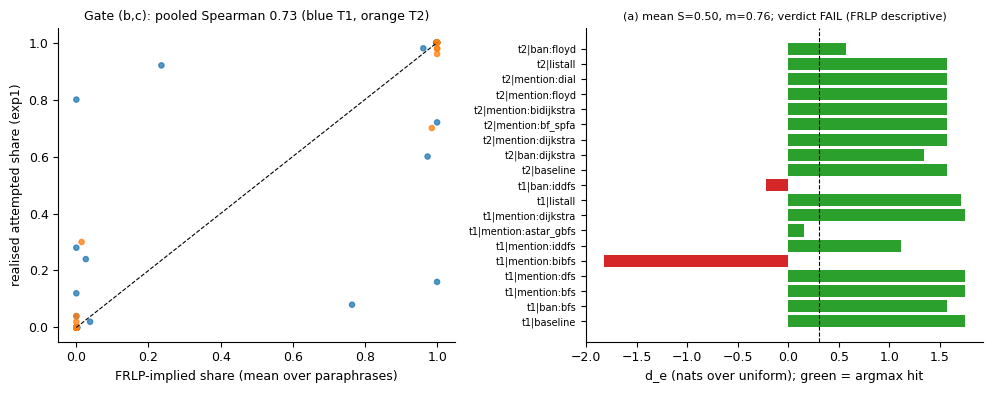

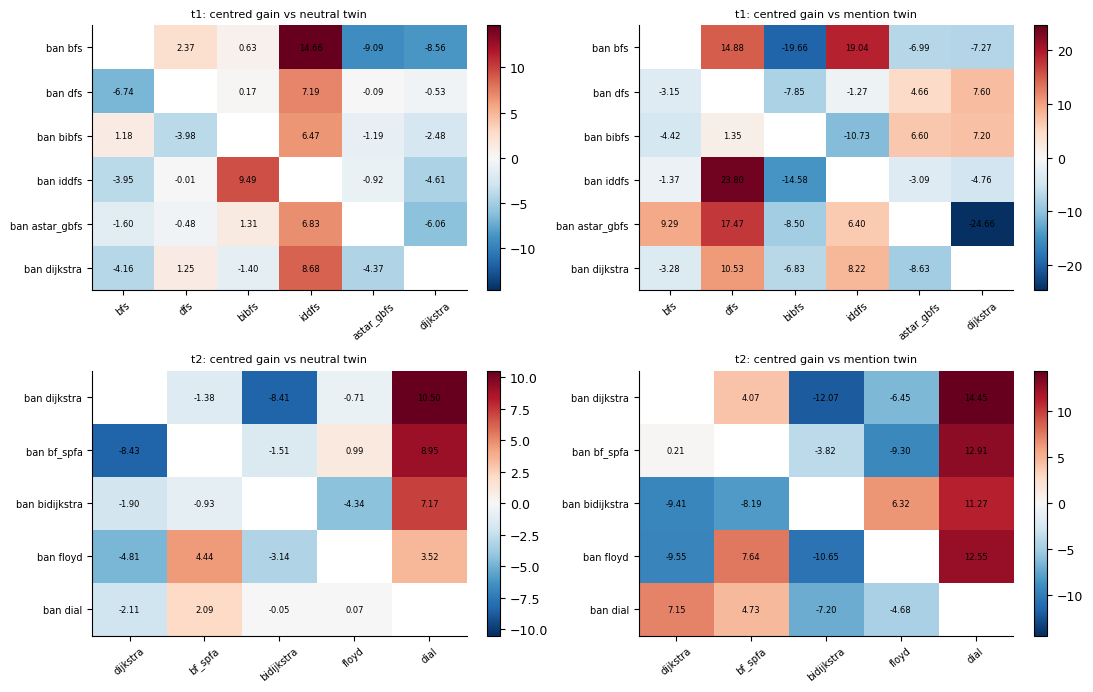

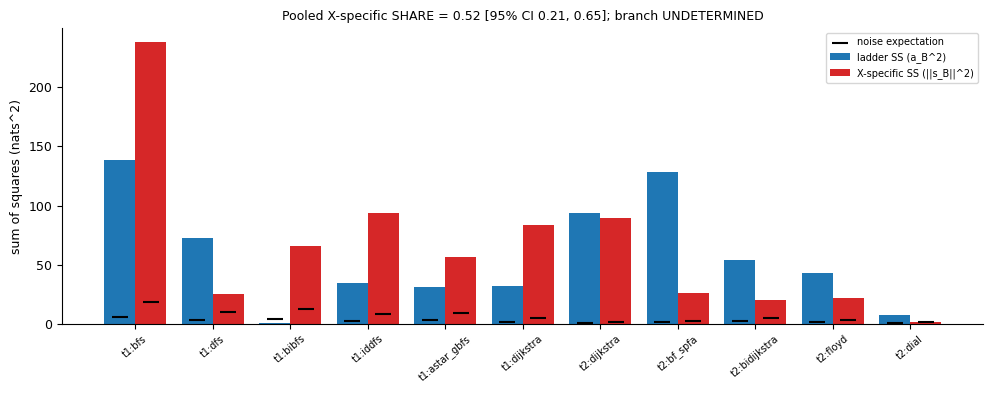

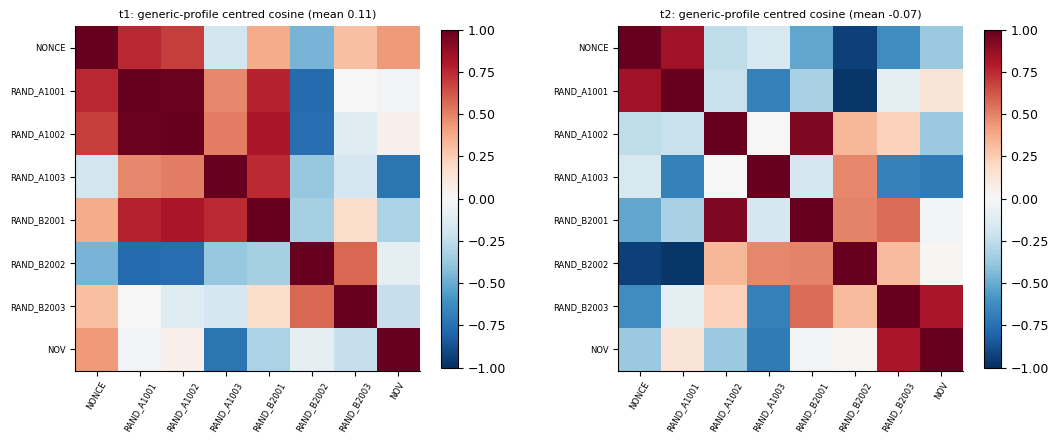

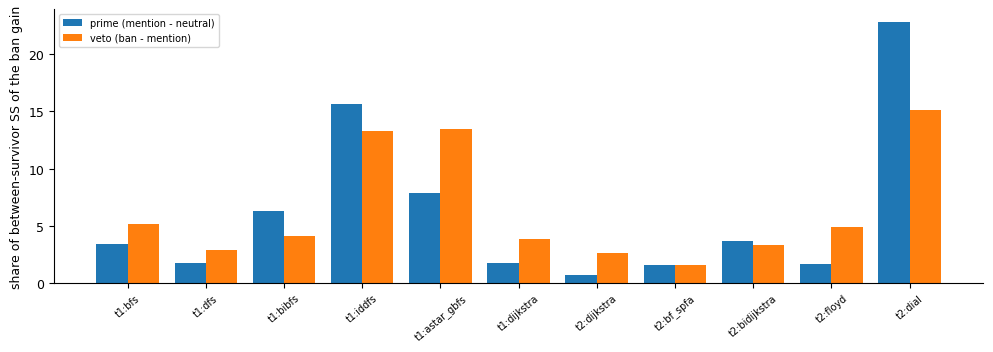

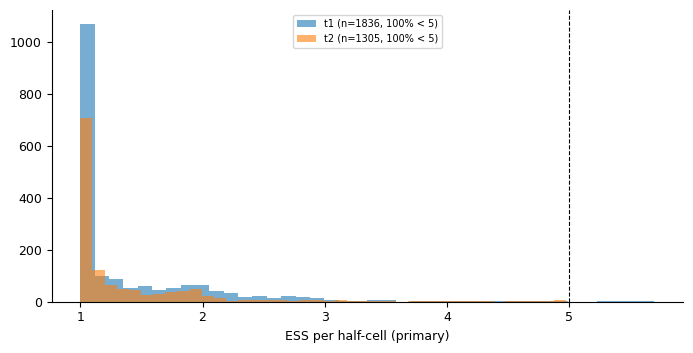

In [20]:
# outputs.py figure functions; `fig.savefig(FIGS / ...)` + `plt.close(fig)` replaced by `plt.show()`
def fig_gate(gate: dict[str, Any]) -> None:
    ev = gate["primary"]["events"]
    fig, axes = plt.subplots(1, 2, figsize=(10, 4))
    xs, ys, cs = [], [], []
    for e in ev:
        n = sum(v for v in e["realised_allowed"].values()) or 1
        for j, q in e["implied_mean"].items():
            xs.append(q)
            ys.append(e["realised_allowed"].get(j, 0) / n)
            cs.append("tab:blue" if e["event_id"].startswith("t1") else "tab:orange")
    axes[0].scatter(xs, ys, c=cs, s=14, alpha=0.75)
    axes[0].plot([0, 1], [0, 1], "k--", lw=0.8)
    axes[0].set_xlabel("FRLP-implied share (mean over paraphrases)")
    axes[0].set_ylabel("realised attempted share (exp1)")
    axes[0].set_title(f"Gate (b,c): pooled Spearman {gate['primary']['pooled_spearman_implied_vs_realised']:.2f} "
                      "(blue T1, orange T2)", fontsize=9)
    names = [e["event_id"] for e in ev]
    d = [e["d_e"] for e in ev]
    axes[1].barh(range(len(names)), d, color=["tab:green" if e["hit"] else "tab:red" for e in ev])
    axes[1].axvline(0.3, color="k", ls="--", lw=0.8)
    axes[1].set_yticks(range(len(names)))
    axes[1].set_yticklabels(names, fontsize=7)
    axes[1].set_xlabel("d_e (nats over uniform); green = argmax hit")
    a = gate["primary"]["a"]
    axes[1].set_title(f"(a) mean S={a['mean_S']:.2f}, m={a['mean_m_default']:.2f}; verdict {gate['verdict']}",
                      fontsize=8)
    fig.tight_layout()
    plt.show()


def fig_heatmaps(c1: dict[str, Any]) -> None:
    fig, axes = plt.subplots(2, 2, figsize=(11, 7))
    for ci, key in enumerate(("primary_neutral", "reference_mention")):
        for ti, t in enumerate(TASKS):
            ax = axes[ti, ci]
            rows = c1[key]["tasks"][t]["rows"]
            js_ = c1[key]["tasks"][t]["measurable"]
            M = np.full((len(MODES[t]), len(js_)), np.nan)
            for bi, B in enumerate(MODES[t]):
                if B in rows:
                    for j, v in rows[B]["Gbar"].items():
                        M[bi, js_.index(j)] = v
            lim = np.nanmax(np.abs(M)) if np.isfinite(M).any() else 1
            im = ax.imshow(M, cmap="RdBu_r", vmin=-lim, vmax=lim, aspect="auto")
            ax.set_xticks(range(len(js_)))
            ax.set_xticklabels(js_, rotation=40, fontsize=7)
            ax.set_yticks(range(len(MODES[t])))
            ax.set_yticklabels([f"ban {b}" for b in MODES[t]], fontsize=7)
            for (i, k), v in np.ndenumerate(M):
                if np.isfinite(v):
                    ax.text(k, i, f"{v:.2f}", ha="center", va="center", fontsize=6)
            ax.set_title(f"{t}: centred gain vs {'neutral' if ci == 0 else 'mention'} twin", fontsize=8)
            fig.colorbar(im, ax=ax, fraction=0.04)
    fig.tight_layout()
    plt.show()


def fig_share(c1: dict[str, Any]) -> None:
    P = c1["primary_neutral"]
    labels, lad, spec, nu, ns = [], [], [], [], []
    for t in TASKS:
        for B, r in P["tasks"][t]["rows"].items():
            labels.append(f"{t}:{B}")
            lad.append(r["a2"])
            spec.append(r["ss_s"])
            nu.append(r["N_u"])
            ns.append(r["N_s"])
    x = np.arange(len(labels))
    fig, ax = plt.subplots(figsize=(10, 4))
    ax.bar(x - 0.2, lad, 0.4, label="ladder SS (a_B^2)", color="tab:blue")
    ax.bar(x + 0.2, spec, 0.4, label="X-specific SS (||s_B||^2)", color="tab:red")
    ax.scatter(x - 0.2, nu, marker="_", color="k", s=120, label="noise expectation")
    ax.scatter(x + 0.2, ns, marker="_", color="k", s=120)
    ax.set_xticks(x)
    ax.set_xticklabels(labels, rotation=40, fontsize=7)
    pb = P["pooled"].get("bootstrap", {})
    sp = P["pooled"]["share_point"]
    ci = pb.get("SHARE_ci", [math.nan, math.nan])
    ax.set_title(f"Pooled X-specific SHARE = {sp['SHARE']:.2f} [95% CI {ci[0]:.2f}, {ci[1]:.2f}]; "
                 f"branch {P['pooled'].get('branch')}", fontsize=9)
    ax.set_ylabel("sum of squares (nats^2)")
    ax.legend(fontsize=7)
    fig.tight_layout()
    plt.show()


def fig_cos(c1: dict[str, Any]) -> None:
    fig, axes = plt.subplots(1, 2, figsize=(11, 4.5))
    for ax, t in zip(axes, TASKS):
        le = c1["primary_neutral"]["tasks"][t].get("ladder_exists", {})
        mat = le.get("matrix", {})
        names = list(mat)
        M = np.array([[mat[a][b] for b in names] for a in names]) if names else np.zeros((1, 1))
        im = ax.imshow(M, cmap="RdBu_r", vmin=-1, vmax=1)
        ax.set_xticks(range(len(names)))
        ax.set_xticklabels(names, rotation=60, fontsize=6)
        ax.set_yticks(range(len(names)))
        ax.set_yticklabels(names, fontsize=6)
        ax.set_title(f"{t}: generic-profile centred cosine (mean {le.get('mean_pairwise_centred_cosine', math.nan):.2f})",
                     fontsize=8)
        fig.colorbar(im, ax=ax, fraction=0.04)
    fig.tight_layout()
    plt.show()


def fig_prime_veto(c1: dict[str, Any]) -> None:
    P = c1["primary_neutral"]
    labels, pr, ve = [], [], []
    for t in TASKS:
        for B, x in P["tasks"][t].get("extras", {}).items():
            labels.append(f"{t}:{B}")
            pr.append(x["prime_share_of_ss"])
            ve.append(x["veto_share_of_ss"])
    x = np.arange(len(labels))
    fig, ax = plt.subplots(figsize=(10, 3.6))
    ax.bar(x - 0.2, pr, 0.4, label="prime (mention - neutral)")
    ax.bar(x + 0.2, ve, 0.4, label="veto (ban - mention)")
    ax.set_xticks(x)
    ax.set_xticklabels(labels, rotation=40, fontsize=7)
    ax.set_ylabel("share of between-survivor SS of the ban gain")
    ax.legend(fontsize=7)
    fig.tight_layout()
    plt.show()


def fig_ess() -> None:
    rows = frlp_cells                                  # read_jsonl(RESULTS / "frlp_cells.jsonl")
    fig, ax = plt.subplots(figsize=(7, 3.6))
    for t, c in (("t1", "tab:blue"), ("t2", "tab:orange")):
        e = [r["ess"] for r in rows if r["task"] == t and r["variant"] == "primary" and r["half"] != "all"
             and r["ess"] is not None]
        if e:
            ax.hist(e, bins=40, alpha=0.6, label=f"{t} (n={len(e)}, {np.mean(np.array(e) < 5):.0%} < 5)", color=c)
    ax.axvline(5, color="k", ls="--", lw=0.8)
    ax.set_xlabel("ESS per half-cell (primary)")
    ax.legend(fontsize=7)
    fig.tight_layout()
    plt.show()


# outputs.main()
for fn, arg in ((fig_gate, gate_out), (fig_heatmaps, c1_out), (fig_share, c1_out), (fig_cos, c1_out),
                (fig_prime_veto, c1_out)):
    fn(arg)
fig_ess()

## Summary

With the default configuration (9 programs per algorithm, full-run bootstrap and null sizes), the demo reaches the full run's conclusions on less than half of the data:

* **FRLP validity gate: FAIL on calibration (a), pass on (b) and (c), as in the full run.** Under the T1 baseline, the name-scrubbed programs give DFS a large share (m = 0.76 < 0.9), although iteration 1 sampled BFS almost always. The **unscrubbed** programs pass all three criteria (m = 1.00). So the failure comes from scrubbing: a scrubbed program is much less likely under its own forced prompts (which name the algorithm) than under a neutral prompt, which inflates the weights of minority algorithms.
* **C1 share test (neutral twins): UNDETERMINED.** The pooled X-specific SHARE is 0.52 [0.21, 0.65] (full run 0.55 [0.25, 0.67]). The gains are far above replicate noise, so this is not pure subtraction, but the CI straddles 0.5.
* **No aimed substitute and no coherent ladder.** The X-specific residuals are not aimed at the prime-and-veto or association profiles (AIM ≈ 0, p ≈ 0.5). The 8 generic profiles disagree with each other (mean centred cosine 0.11 on T1, −0.07 on T2).
* **Bans prime the banned name.** In 8 of 11 rows, banning an algorithm raises its own FRLP. Examples: +26.5 nats for bidirectional BFS, +22.2 for IDDFS, +21.0 for Dial. Only the bans of the modal algorithms (BFS, Dijkstra on T2) and of A* lower it, the same pattern as in the full run.
* **Where the subset differs from the full run.**
  * With fewer programs per cell, the mention-twin and ESS-weighted references turn X-SPECIFIC-UNAIMED, so the pooled branch is not robust here (it was in the full run).
  * The `correct_only` variant becomes unstable.
  * Nearly every cell rests on an ESS close to 1, so all numbers are descriptive, as in the full run.
* **Audit.** The independent re-derivation matches every headline number (differences ≤ 1e-15), and the placebo AIM sits at its null.

**Checking against the full run.** `build_mini_demo_data.py --m 20` builds the full score data (211 programs). With `M_SCORED = 20`, the code in this notebook reproduces the artifact's published gate, C1 SHARE, AIM and sensitivity numbers to within 1e-7; the scores are stored with 6 decimals.